# Urban Infrastructure Pulse Intelligence —  NYC 311 EDA (2023–2025)

**Input:** `config.MASTER_DATA_FILE` (`data/processed/nyc311_infrastructure_cleaned.csv`), containing the 15 selected complaint categories.



In [1]:
import sys
from pathlib import Path

# Find project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Add project root to Python import path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Python path configured successfully.")

Project root: d:\Urban-Infrastructure-Pulse-Intelligence
Python path configured successfully.


### Import libraries

In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Project configuration and data loading
from config.config import (
    EDA_FIGURES_DIR, EDA_TABLES_DIR, REPORTS_DIR, PROCESSED_DATA_DIR
)
from src.data.load_data import load_master_data

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid")
for directory in [EDA_FIGURES_DIR, EDA_TABLES_DIR, REPORTS_DIR, PROCESSED_DATA_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
print("EDA environment initialized successfully.")


EDA environment initialized successfully.


### Load the master dataset

In [3]:
df = load_master_data()

# Verify expected study scope without assuming a fixed sample size.
required = {"unique_key", "created_date", "complaint_type", "borough", "latitude", "longitude"}
missing_required = required - set(df.columns)
if missing_required:
    raise ValueError(f"Required columns missing: {sorted(missing_required)}")

created_dates_check = pd.to_datetime(df["created_date"], errors="coerce")
outside_study = ~created_dates_check.between(
    "2023-01-01", "2025-12-31 23:59:59.999999"
)
if outside_study.any():
    raise ValueError(f"{int(outside_study.sum()):,} records have invalid/out-of-range creation dates.")

print(f"Dataset loaded: {len(df):,} records, {df.shape[1]} columns")
print("Complaint types:", df["complaint_type"].nunique(dropna=True))
print("Study dates:", created_dates_check.min(), "to", created_dates_check.max())
print("Note: all figures and conclusions below are recomputed from this dataset.")


Dataset loaded: 685,284 records, 53 columns
Complaint types: 15
Study dates: 2023-01-01 00:00:57 to 2025-12-31 23:57:00
Note: all figures and conclusions below are recomputed from this dataset.


In [4]:
display(df.head())

,unique_key,created_date,closed_date,agency,agency_name,complaint_type,descriptor,descriptor_2,location_type,incident_zip,incident_address,street_name,cross_street_1,cross_street_2,intersection_street_1,intersection_street_2,address_type,city,landmark,facility_type,status,due_date,resolution_description,resolution_action_updated_date,community_board,council_district,police_precinct,bbl,borough,x_coordinate_state_plane,y_coordinate_state_plane,open_data_channel_type,park_facility_name,park_borough,vehicle_type,taxi_company_borough,taxi_pick_up_location,bridge_highway_name,bridge_highway_direction,road_ramp,bridge_highway_segment,latitude,longitude,location,created_year,created_month,created_day_of_week,resolution_hours,has_valid_coordinates,coordinate_quality_flag,date_quality_flag,has_closed_date,is_closed_status
0,56408061,2023-01-01T00:32:00.000,2023-01-01T01:30:00.000,DOT,Department of Transportation,Traffic Signal Condition,Controller,Allout,NaN,NaN,NaN,NaN,NaN,NaN,NAVY ST,PARK AVE,INTERSECTION,NaN,NaN,NaN,Closed,NaN,Service Request status for this request is ava...,2023-01-01T01:30:00.000,Unspecified BROOKLYN,NaN,Unspecified,NaN,BROOKLYN,NaN,NaN,UNKNOWN,Unspecified,BROOKLYN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2023,1,Sunday,0.97,False,missing_or_non_numeric_coordinate,valid_or_not_evaluable,True,True
1,56409451,2023-01-01T00:18:00.000,2023-01-01T03:40:00.000,DOT,Department of Transportation,Traffic Signal Condition,Controller,Operating Improperly,NaN,11208.00,NaN,NaN,NaN,NaN,LIBERTY AVENUE,SHEPHERD AVENUE,INTERSECTION,BROOKLYN,NaN,NaN,Closed,NaN,Service Request status for this request is ava...,2023-01-01T03:40:00.000,05 BROOKLYN,37.00,Precinct 75,NaN,BROOKLYN,1017139.00,185815.00,UNKNOWN,Unspecified,BROOKLYN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.68,-73.88,POINT (-73.881428919213 40.676634912459),2023,1,Sunday,3.37,True,valid_coordinate_range,valid_or_not_evaluable,True,True
2,56410624,2023-01-01T00:25:00.000,2023-01-01T05:50:00.000,DOT,Department of Transportation,Traffic Signal Condition,Controller,Operating Improperly,NaN,11358.00,NaN,NaN,NaN,NaN,NORTHERN BOULEVARD,162 STREET,INTERSECTION,QUEENS,NaN,NaN,Closed,NaN,Service Request status for this request is ava...,2023-01-01T05:50:00.000,07 QUEENS,20.00,Precinct 109,NaN,QUEENS,1038618.00,217003.00,UNKNOWN,Unspecified,QUEENS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.76,-73.80,POINT (-73.803741344846 40.762132385932),2023,1,Sunday,5.42,True,valid_coordinate_range,valid_or_not_evaluable,True,True
3,56410653,2023-01-01T00:52:00.000,2023-01-01T03:50:00.000,DOT,Department of Transportation,Traffic Signal Condition,Controller,Operating Improperly,NaN,11102.00,NaN,NaN,NaN,NaN,NEWTOWN AVENUE,31 STREET,INTERSECTION,QUEENS,NaN,NaN,Closed,NaN,Service Request status for this request is ava...,2023-01-01T03:50:00.000,01 QUEENS,22.00,Precinct 114,NaN,QUEENS,1006197.00,218962.00,UNKNOWN,Unspecified,QUEENS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.77,-73.92,POINT (-73.920768788821 40.767649260236),2023,1,Sunday,2.97,True,valid_coordinate_range,valid_or_not_evaluable,True,True
4,56411233,2023-01-01T00:18:00.000,2023-01-01T03:40:00.000,DOT,Department of Transportation,Traffic Signal Condition,Controller,Operating Improperly,NaN,11208.00,NaN,NaN,NaN,NaN,LIBERTY AVENUE,SHEPHERD AVENUE,INTERSECTION,BROOKLYN,NaN,NaN,Closed,NaN,Service Request status for this request is ava...,2023-01-01T03:40:00.000,05 BROOKLYN,37.00,Precinct 75,NaN,BROOKLYN,1017139.00,185815.00,UNKNOWN,Unspecified,BROOKLYN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.68,-73.88,POINT (-73.881428919213 40.676634912459),2023,1,Sunday,3.37,True,valid_coordinate_range,valid_or_not_evaluable,True,True


In [5]:
# Avoid doing high-cardinality unique-value scans on every free-text field.
core_unique_columns = [
    "complaint_type", "borough", "agency", "status", "created_year",
    "created_month", "date_quality_flag", "coordinate_quality_flag",
]
unique_counts = {col: int(df[col].nunique(dropna=True))
                 for col in core_unique_columns if col in df.columns}

column_summary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
    "Missing Count": df.isna().sum().values,
    "Unique Values (selected fields)": [unique_counts.get(c, pd.NA) for c in df.columns],
})
display(column_summary)


,Column,Data Type,Non-Null Count,Missing Count,Unique Values (selected fields)
0,unique_key,int64,685284,0,<NA>
1,created_date,str,685284,0,<NA>
2,closed_date,str,667741,17543,<NA>
3,agency,str,685284,0,5
4,agency_name,str,685284,0,<NA>
5,complaint_type,str,685284,0,15
6,descriptor,str,685284,0,<NA>
7,descriptor_2,str,420000,265284,<NA>
8,location_type,str,259108,426176,<NA>
9,incident_zip,float64,668677,16607,<NA>


In [6]:
column_summary.to_csv(
    EDA_TABLES_DIR / "column_summary.csv",
    index=False
)

In [7]:
display(df.describe(include="number").T)

,count,mean,std,min,25%,50%,75%,max
unique_key,685284.00,61771595.47,3182335.45,56408061.00,59024905.75,61640227.00,64612688.25,67401512.00
incident_zip,668677.00,10911.61,530.78,83.00,10452.00,11212.00,11360.00,12345.00
facility_type,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
due_date,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
council_district,610746.00,27.68,14.70,1.00,16.00,29.00,40.00,51.00
bbl,329502.00,3169558227.04,1175515516.11,0.00,2058640501.25,3066150048.50,4068470003.00,5270000523.00
x_coordinate_state_plane,611294.00,1005189.36,27183.24,913353.00,989924.00,1004038.00,1023581.75,1067281.00
y_coordinate_state_plane,611330.00,198414.88,30109.96,121098.00,176331.50,197303.00,217286.00,271876.00
vehicle_type,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
taxi_company_borough,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# Full source datasets may contain long free-text fields. Summarize only
# interpretable categorical fields instead of scanning every text column.
categorical_columns = [
    c for c in ["complaint_type", "borough", "agency", "status",
                "date_quality_flag", "coordinate_quality_flag"]
    if c in df.columns
]
display(df[categorical_columns].describe().T)


,count,unique,top,freq
complaint_type,685284,15,Street Condition,205581
borough,685284,6,QUEENS,223819
agency,685284,5,DOT,566184
status,685284,7,Closed,661133
date_quality_flag,685284,3,valid_or_not_evaluable,662118
coordinate_quality_flag,685284,2,valid_coordinate_range,611284


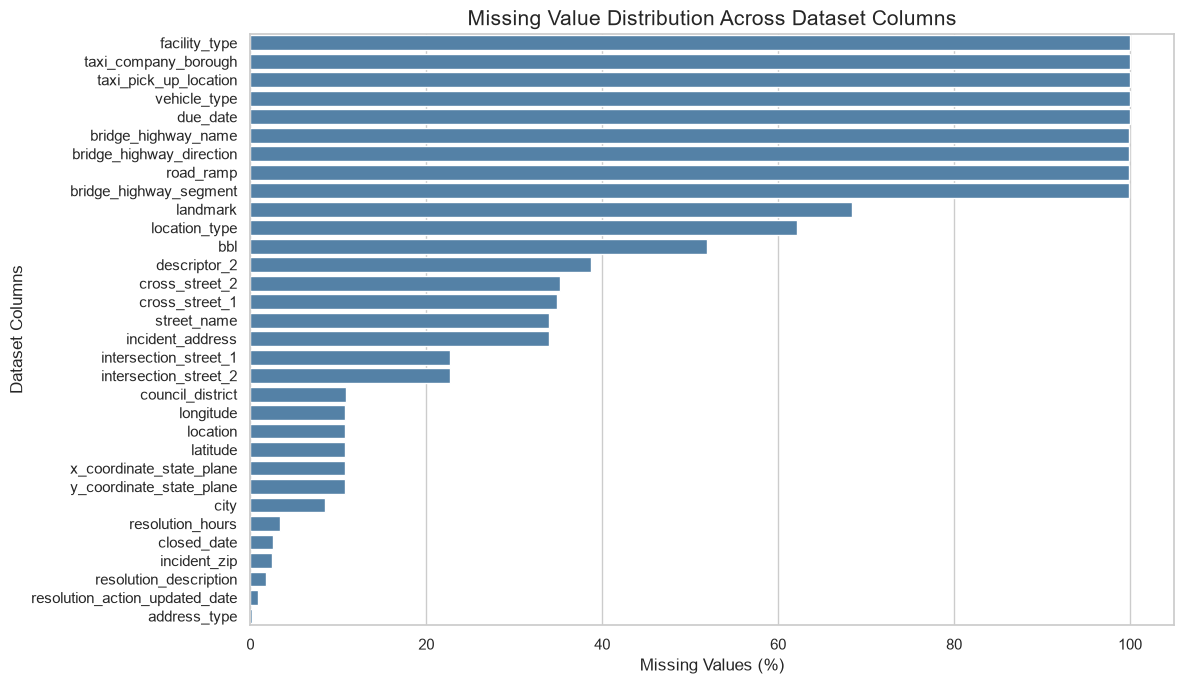

In [9]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    )
})

missing_summary = missing_summary.sort_values(
    "Missing Percentage",
    ascending=False
)

missing_summary.to_csv(
    EDA_TABLES_DIR / "missing_values_summary.csv"
)

plot_data = missing_summary[
    missing_summary["Missing Count"] > 0
]

plt.figure(figsize=(12, 7))

sns.barplot(
    color="steelblue",
    data=plot_data.reset_index(),
    x="Missing Percentage",
    y="index"
)

plt.title(
    "Missing Value Distribution Across Dataset Columns",
    fontsize=15
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Dataset Columns")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "missing_values_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
missing_analysis = missing_summary.copy()

def classify_missingness(column):

    if column == "due_date":
        return "Completely Empty"

    elif column in [
        "latitude",
        "longitude",
        "location",
        "resolution_hours",
        "closed_date"
    ]:
        return "Analytically Important"

    elif column in [
        "created_date",
        "complaint_type",
        "borough",
        "unique_key"
    ]:
        return "Core Fields"

    else:
        return "Descriptive Fields"


missing_analysis["Field Group"] = (
    missing_analysis.index.map(classify_missingness)
)

display(
    missing_analysis[
        missing_analysis["Missing Count"] > 0
    ]
)

,Missing Count,Missing Percentage,Field Group
facility_type,685284,100.00,Descriptive Fields
taxi_company_borough,685284,100.00,Descriptive Fields
taxi_pick_up_location,685284,100.00,Descriptive Fields
vehicle_type,685284,100.00,Descriptive Fields
due_date,685284,100.00,Completely Empty
bridge_highway_name,684428,99.88,Descriptive Fields
bridge_highway_direction,684428,99.88,Descriptive Fields
road_ramp,684428,99.88,Descriptive Fields
bridge_highway_segment,684428,99.88,Descriptive Fields
landmark,468417,68.35,Descriptive Fields


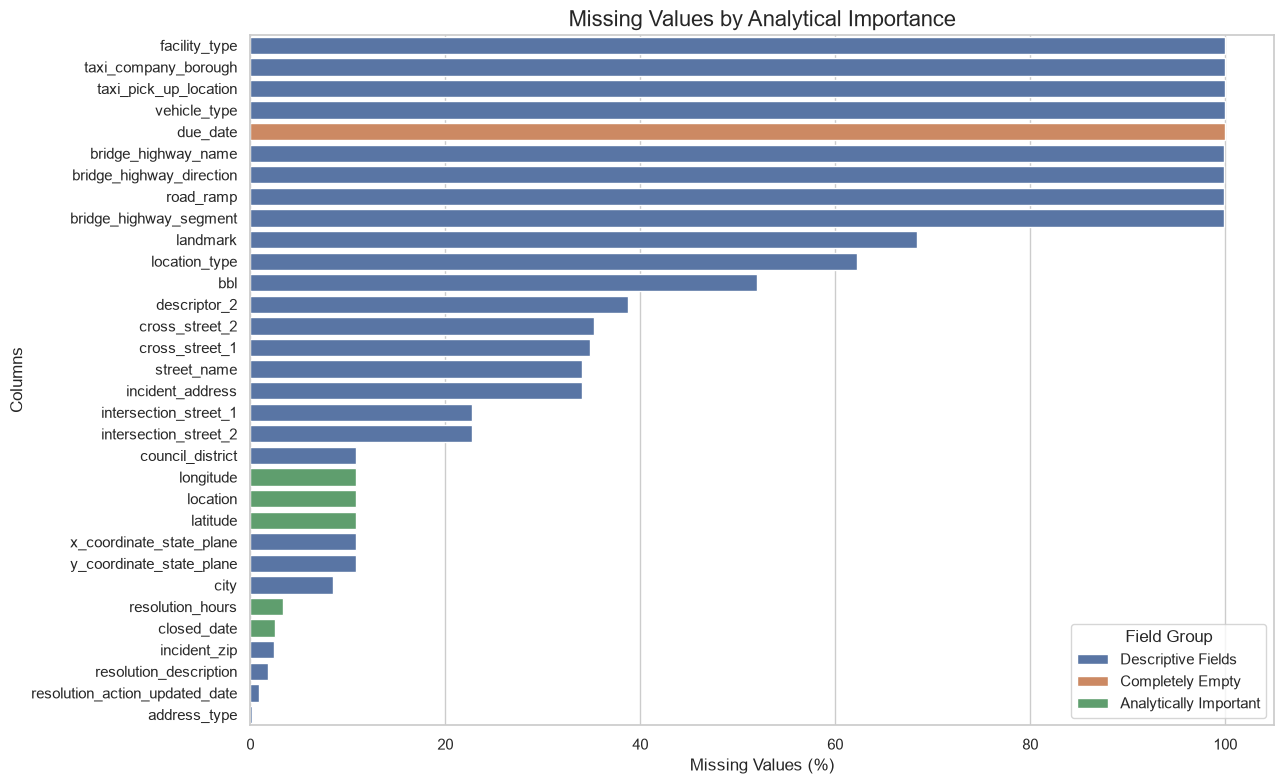

In [11]:
plot_df = missing_analysis[
    missing_analysis["Missing Count"] > 0
].copy()

plt.figure(figsize=(13, 8))

sns.barplot(
    data=plot_df.reset_index(),
    x="Missing Percentage",
    y="index",
    hue="Field Group",
    dodge=False
)

plt.title(
    "Missing Values by Analytical Importance",
    fontsize=16
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Columns")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "missingness_by_field_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
# Derive data quality findings from the current data, not historical 100K figures.
missing_geo = int((df["latitude"].isna() | df["longitude"].isna()).sum())
missing_resolution = int(df["resolution_hours"].isna().sum())
backward_dates = int((df["date_quality_flag"] == "closed_before_created").sum())     if "date_quality_flag" in df.columns else None
quality_findings = [
    f"The cleaned dataset contains {len(df):,} complaint records and {df.shape[1]} columns.",
    f"There are {df['complaint_type'].nunique(dropna=True)} complaint categories.",
    f"Duplicate complaint IDs: {int(df['unique_key'].duplicated().sum()):,}.",
    f"Missing complaint IDs: {int(df['unique_key'].isna().sum()):,}.",
    f"Missing creation dates: {int(df['created_date'].isna().sum()):,}.",
    f"Missing coordinate pairs: {missing_geo:,} ({missing_geo/len(df)*100:.2f}%).",
    f"Unavailable resolution durations: {missing_resolution:,} ({missing_resolution/len(df)*100:.2f}%).",
    f"Backward closing timestamps flagged: {backward_dates:,}." if backward_dates is not None
        else "Backward timestamp count not available in this file.",
    "Missing or invalid coordinates must be excluded from spatial plots/DBSCAN.",
    "Complaint closure duration is not necessarily physical repair duration.",
]
if "due_date" in df.columns:
    quality_findings.append(
        f"Missing due dates: {int(df['due_date'].isna().sum()):,} "
        f"({df['due_date'].isna().mean()*100:.2f}%)."
    )

report_path = REPORTS_DIR / "eda_data_quality_findings.txt"
with open(report_path, "w", encoding="utf-8") as file:
    file.write("EDA — DATA QUALITY FINDINGS\n" + "=" * 50 + "\n\n")
    for index, finding in enumerate(quality_findings, start=1):
        file.write(f"{index}. {finding}\n")

print("EDA findings saved:", report_path)
print("\n".join(quality_findings))


EDA findings saved: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\reports\eda_data_quality_findings.txt
The cleaned dataset contains 685,284 complaint records and 53 columns.
There are 15 complaint categories.
Duplicate complaint IDs: 0.
Missing complaint IDs: 0.
Missing creation dates: 0.
Missing coordinate pairs: 74,000 (10.80%).
Unavailable resolution durations: 23,166 (3.38%).
Backward closing timestamps flagged: 5,623.
Missing or invalid coordinates must be excluded from spatial plots/DBSCAN.
Complaint closure duration is not necessarily physical repair duration.
Missing due dates: 685,284 (100.00%).


### Section 2: Complaint Category Analysis

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [14]:
print("Number of unique complaint categories:",
      df["complaint_type"].nunique())

print("\nAvailable categories:")

print(
    sorted(df["complaint_type"].dropna().unique())
)

Number of unique complaint categories: 15

Available categories:
['Bridge Condition', 'Curb Condition', 'Root/Sewer/Sidewalk Condition', 'Sewer', 'Sewer Maintenance', 'Sidewalk Condition', 'Street Condition', 'Street Light Condition', 'Street Sign - Damaged', 'Street Sign - Dangling', 'Street Sign - Missing', 'Traffic Signal Condition', 'Water Drainage', 'Water Leak', 'Water Maintenance']


In [15]:
category_summary = (
    df["complaint_type"]
    .value_counts()
    .reset_index()
)

category_summary.columns = [
    "complaint_category",
    "complaint_count"
]

category_summary["percentage"] = (
    category_summary["complaint_count"]
    / len(df) * 100
).round(2)

category_summary["cumulative_percentage"] = (
    category_summary["percentage"].cumsum()
).round(2)

display(category_summary)

,complaint_category,complaint_count,percentage,cumulative_percentage
0,Street Condition,205581,30.00,30.00
1,Traffic Signal Condition,129490,18.90,48.90
2,Street Light Condition,99259,14.48,63.38
3,Sewer,82230,12.00,75.38
4,Sidewalk Condition,73809,10.77,86.15
5,Root/Sewer/Sidewalk Condition,30171,4.40,90.55
6,Curb Condition,21236,3.10,93.65
7,Street Sign - Damaged,14976,2.19,95.84
8,Street Sign - Dangling,10585,1.54,97.38
9,Street Sign - Missing,10408,1.52,98.90


In [16]:
category_summary.to_csv(
    EDA_TABLES_DIR / "category_summary.csv",
    index=False
)

print("Category summary saved successfully.")

Category summary saved successfully.


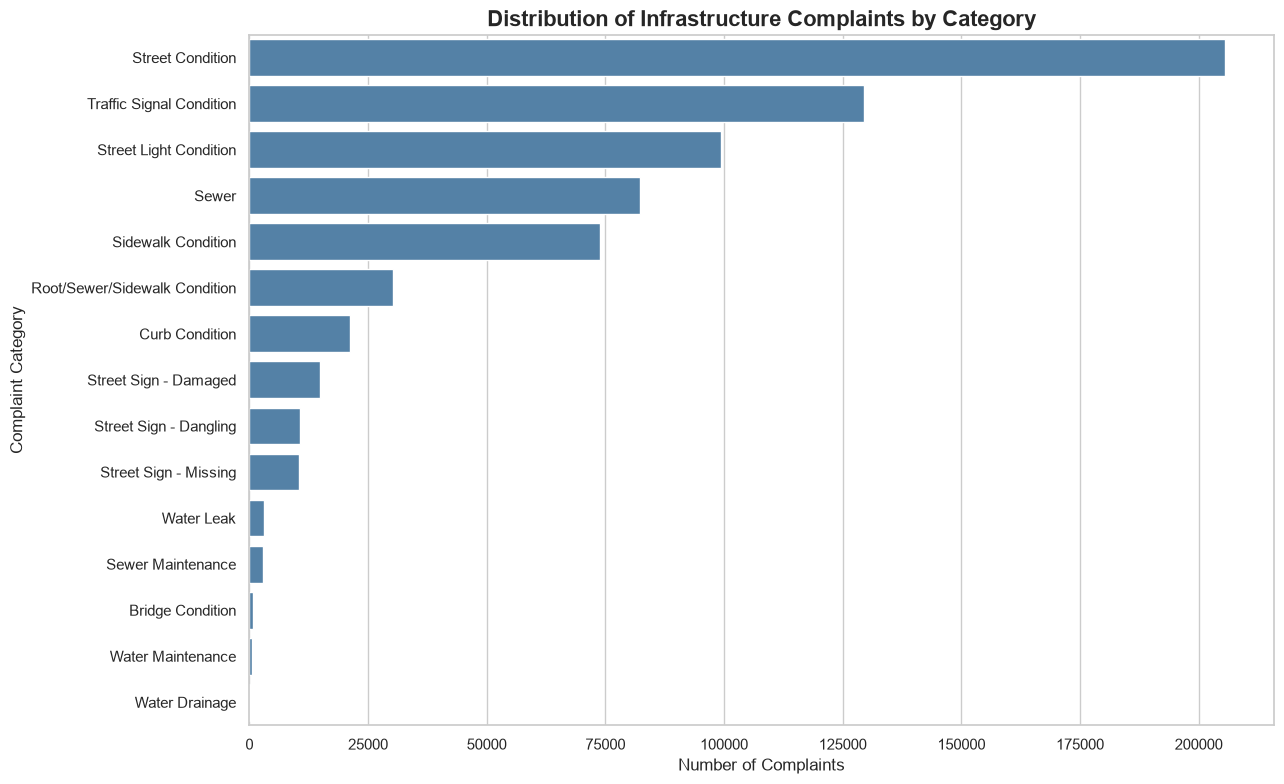

In [17]:
plt.figure(figsize=(13, 8))

sns.barplot(
    color="steelblue",
    data=category_summary,
    x="complaint_count",
    y="complaint_category"
)

plt.title(
    "Distribution of Infrastructure Complaints by Category",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Complaints")
plt.ylabel("Complaint Category")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "complaint_category_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

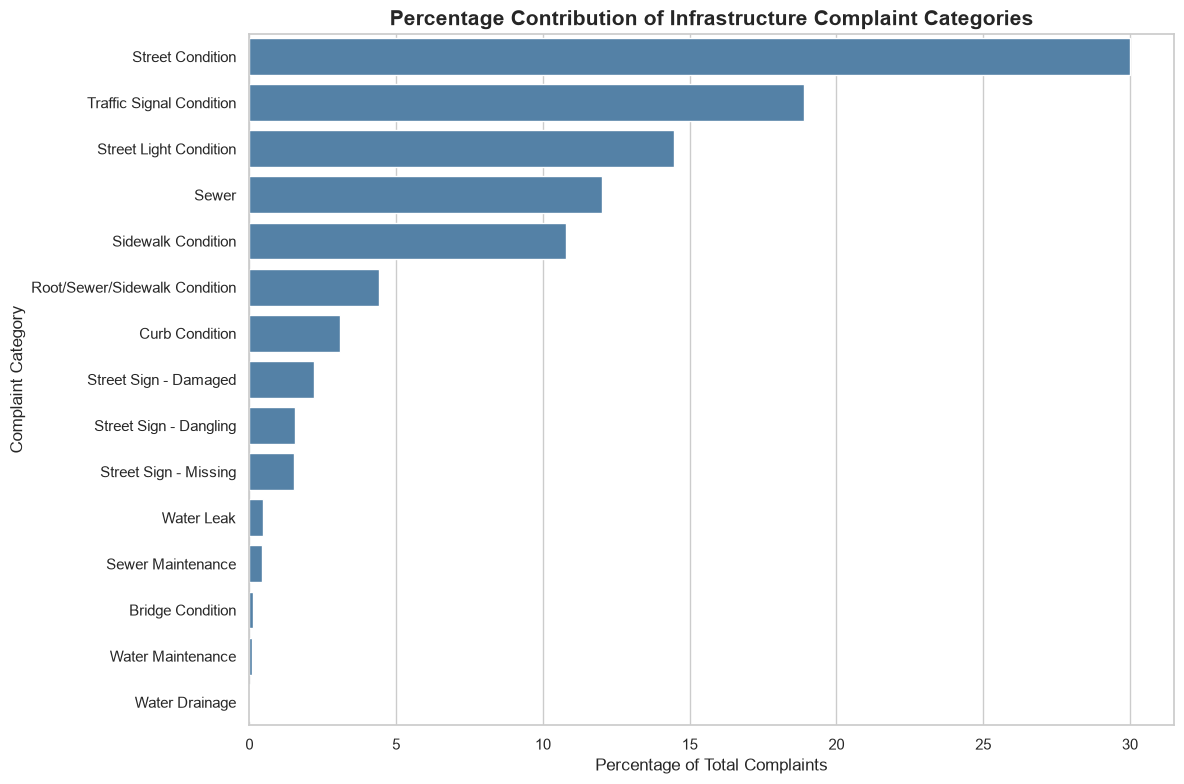

In [18]:
plt.figure(figsize=(12, 8))

sns.barplot(
    color="steelblue",
    data=category_summary,
    x="percentage",
    y="complaint_category"
)

plt.title(
    "Percentage Contribution of Infrastructure Complaint Categories",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Percentage of Total Complaints")
plt.ylabel("Complaint Category")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "category_percentage_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

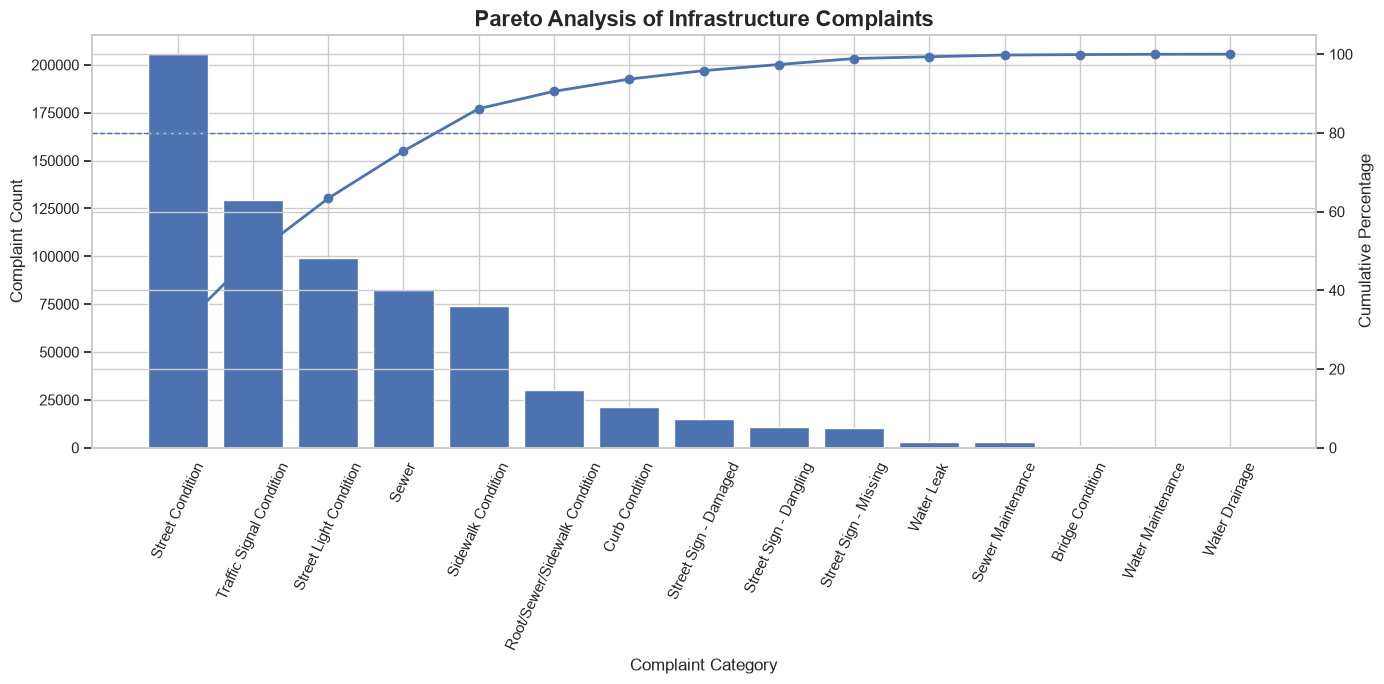

In [19]:
fig, ax1 = plt.subplots(figsize=(14, 7))

categories = category_summary["complaint_category"]
counts = category_summary["complaint_count"]
cumulative = category_summary["cumulative_percentage"]

ax1.bar(
    categories,
    counts
)

ax1.set_xlabel("Complaint Category")
ax1.set_ylabel("Complaint Count")

ax1.tick_params(
    axis="x",
    rotation=65
)

ax2 = ax1.twinx()

ax2.plot(
    categories,
    cumulative,
    marker="o",
    linewidth=2
)

ax2.set_ylabel("Cumulative Percentage")
ax2.set_ylim(0, 105)

ax2.axhline(
    80,
    linestyle="--",
    linewidth=1
)

plt.title(
    "Pareto Analysis of Infrastructure Complaints",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "complaint_category_pareto.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Identify dominant and underrepresented categories

In [20]:
highest_category = category_summary.iloc[0]

lowest_category = category_summary.iloc[-1]

print("CATEGORY ANALYSIS")
print("=" * 55)

print(
    f"\nHighest complaint category: "
    f"{highest_category['complaint_category']}"
)

print(
    f"Complaint count: "
    f"{highest_category['complaint_count']:,}"
)

print(
    f"Contribution: "
    f"{highest_category['percentage']}%"
)

print("\n")

print(
    f"Lowest complaint category: "
    f"{lowest_category['complaint_category']}"
)

print(
    f"Complaint count: "
    f"{lowest_category['complaint_count']:,}"
)

print(
    f"Contribution: "
    f"{lowest_category['percentage']}%"
)

CATEGORY ANALYSIS

Highest complaint category: Street Condition
Complaint count: 205,581
Contribution: 30.0%


Lowest complaint category: Water Drainage
Complaint count: 136
Contribution: 0.02%


Category concentration summary

In [21]:
top_3_percentage = category_summary.head(3)["percentage"].sum()
top_5_percentage = category_summary.head(5)["percentage"].sum()
print("CATEGORY CONCENTRATION")
print("=" * 45)
print(f"Top 3 categories: {top_3_percentage:.2f}%")
print(f"Top 5 categories: {top_5_percentage:.2f}%")
print("Remaining categories:", max(len(category_summary) - 5, 0))


CATEGORY CONCENTRATION
Top 3 categories: 63.38%
Top 5 categories: 86.15%
Remaining categories: 10


In [22]:
category_findings = {
    "total_records": len(df),
    "total_categories": df["complaint_type"].nunique(),
    "highest_category": highest_category["complaint_category"],
    "highest_category_count": int(
        highest_category["complaint_count"]
    ),
    "lowest_category": lowest_category["complaint_category"],
    "lowest_category_count": int(
        lowest_category["complaint_count"]
    ),
    "top_3_contribution_pct": round(top_3_percentage, 2),
    "top_5_contribution_pct": round(top_5_percentage, 2)
}

category_findings_df = pd.DataFrame(
    [category_findings]
)

display(category_findings_df)

category_findings_df.to_csv(
    EDA_TABLES_DIR / "category_analysis_findings.csv",
    index=False
)

,total_records,total_categories,highest_category,highest_category_count,lowest_category,lowest_category_count,top_3_contribution_pct,top_5_contribution_pct
0,685284,15,Street Condition,205581,Water Drainage,136,63.38,86.15


## Section 2 — Interpretation guidance 

Use the **computed category_summary** and Pareto chart above for final results. 



## Section 3: Temporal Complaint Analysis

#### Prepare temporal feature

In [23]:
# Ensure datetime format
df["created_date"] = pd.to_datetime(
    df["created_date"],
    errors="coerce"
)

# Extract temporal features
df["year"] = df["created_date"].dt.year
df["month"] = df["created_date"].dt.month
df["month_name"] = df["created_date"].dt.month_name()
df["day_of_week"] = df["created_date"].dt.dayofweek
df["day_name"] = df["created_date"].dt.day_name()

df["year_month"] = (
    df["created_date"].dt.to_period("M").astype(str)
)

print("Temporal features created successfully.")

display(df[[
    "created_date",
    "year",
    "month",
    "month_name",
    "day_name",
    "year_month"
]].head())

Temporal features created successfully.


,created_date,year,month,month_name,day_name,year_month
0,2023-01-01 00:32:00,2023,1,January,Sunday,2023-01
1,2023-01-01 00:18:00,2023,1,January,Sunday,2023-01
2,2023-01-01 00:25:00,2023,1,January,Sunday,2023-01
3,2023-01-01 00:52:00,2023,1,January,Sunday,2023-01
4,2023-01-01 00:18:00,2023,1,January,Sunday,2023-01


#### Year-wise complaint analysis

In [24]:
yearly_summary = (
    df.groupby("year")
    .size()
    .reset_index(name="complaint_count")
)

yearly_summary["percentage"] = (
    yearly_summary["complaint_count"] / len(df) * 100
).round(2)

display(yearly_summary)

,year,complaint_count,percentage
0,2023,223782,32.66
1,2024,226150,33.00
2,2025,235352,34.34


In [25]:
yearly_summary.to_csv(
    EDA_TABLES_DIR / "yearly_complaint_summary.csv",
    index=False
)

Year-wise distribution

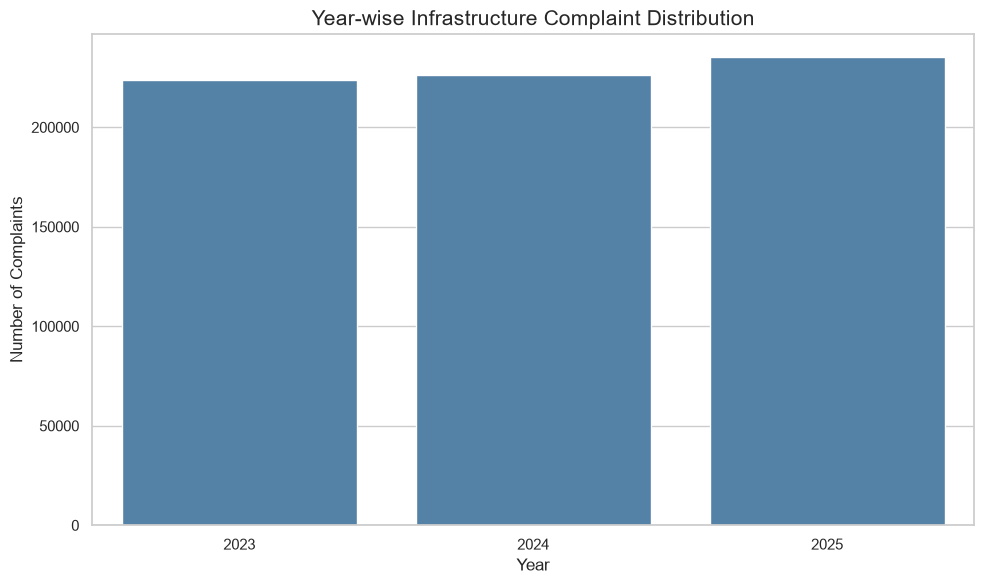

In [26]:
plt.figure(figsize=(10, 6))

sns.barplot(
    color="steelblue",
    data=yearly_summary,
    x="year",
    y="complaint_count"
)

plt.title(
    "Year-wise Infrastructure Complaint Distribution",
    fontsize=15
)

plt.xlabel("Year")
plt.ylabel("Number of Complaints")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "yearly_complaint_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Monthly complaint trends

In [27]:
monthly_summary = (
    df.groupby("year_month")
    .size()
    .reset_index(name="complaint_count")
)

monthly_summary["month_date"] = pd.to_datetime(
    monthly_summary["year_month"]
)

monthly_summary = monthly_summary.sort_values(
    "month_date"
)

display(monthly_summary)

,year_month,complaint_count,month_date
0,2023-01,20390,2023-01-01
1,2023-02,18210,2023-02-01
2,2023-03,21629,2023-03-01
3,2023-04,18265,2023-04-01
4,2023-05,18018,2023-05-01
5,2023-06,16227,2023-06-01
6,2023-07,17330,2023-07-01
7,2023-08,18690,2023-08-01
8,2023-09,23859,2023-09-01
9,2023-10,20137,2023-10-01


In [28]:
monthly_summary.to_csv(
    EDA_TABLES_DIR / "monthly_complaint_summary.csv",
    index=False
)

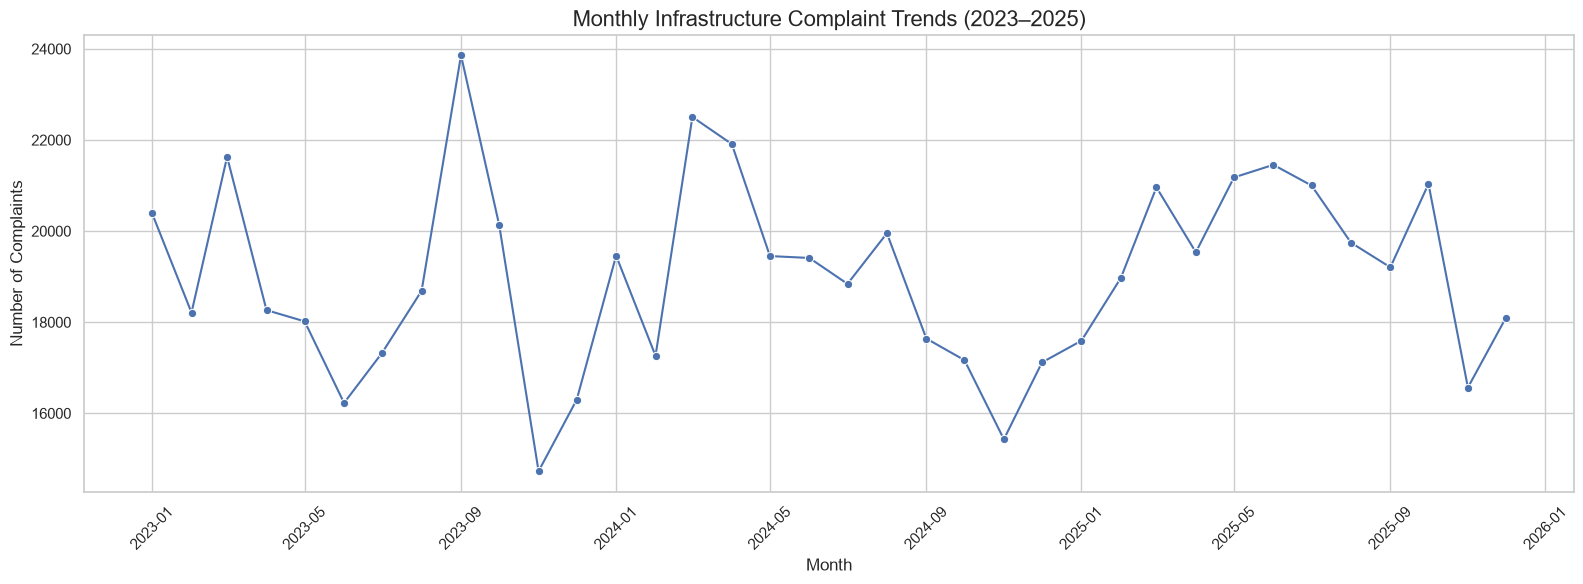

In [29]:
plt.figure(figsize=(16, 6))

sns.lineplot(
    data=monthly_summary,
    x="month_date",
    y="complaint_count",
    marker="o"
)

plt.title(
    "Monthly Infrastructure Complaint Trends (2023–2025)",
    fontsize=16
)

plt.xlabel("Month")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "monthly_complaint_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Seasonal complaint analysis

In [30]:
month_order = [
    "January", "February", "March",
    "April", "May", "June",
    "July", "August", "September",
    "October", "November", "December"
]

seasonal_summary = (
    df.groupby("month_name")
    .size()
    .reindex(month_order)
    .reset_index()
)

seasonal_summary.columns = [
    "month_name",
    "complaint_count"
]

display(seasonal_summary)

,month_name,complaint_count
0,January,57443
1,February,54444
2,March,65095
3,April,59712
4,May,58648
5,June,57092
6,July,57172
7,August,58390
8,September,60705
9,October,58340


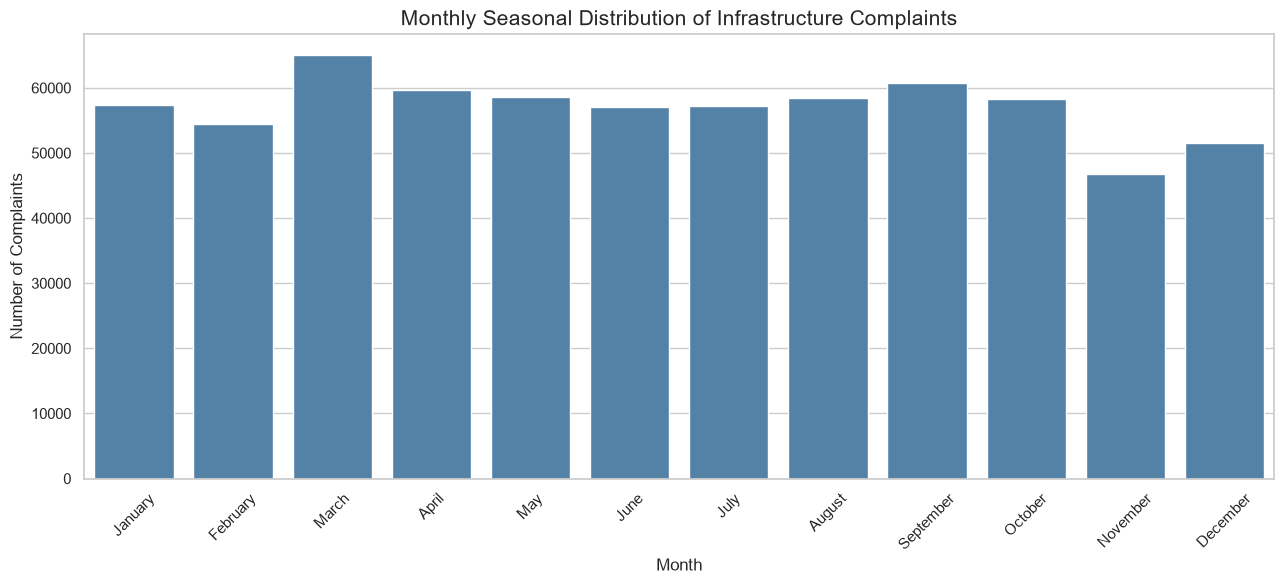

In [31]:
plt.figure(figsize=(13, 6))

sns.barplot(
    color="steelblue",
    data=seasonal_summary,
    x="month_name",
    y="complaint_count"
)

plt.title(
    "Monthly Seasonal Distribution of Infrastructure Complaints",
    fontsize=15
)

plt.xlabel("Month")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "seasonal_complaint_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Weekday analysis

In [32]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_summary = (
    df.groupby("day_name")
    .size()
    .reindex(weekday_order)
    .reset_index()
)

weekday_summary.columns = [
    "day_name",
    "complaint_count"
]

weekday_summary["percentage"] = (
    weekday_summary["complaint_count"] / len(df) * 100
).round(2)

display(weekday_summary)

,day_name,complaint_count,percentage
0,Monday,114493,16.71
1,Tuesday,117548,17.15
2,Wednesday,117647,17.17
3,Thursday,115233,16.82
4,Friday,106070,15.48
5,Saturday,57390,8.37
6,Sunday,56903,8.30


In [33]:
weekday_summary.to_csv(
    EDA_TABLES_DIR / "weekday_complaint_summary.csv",
    index=False
)

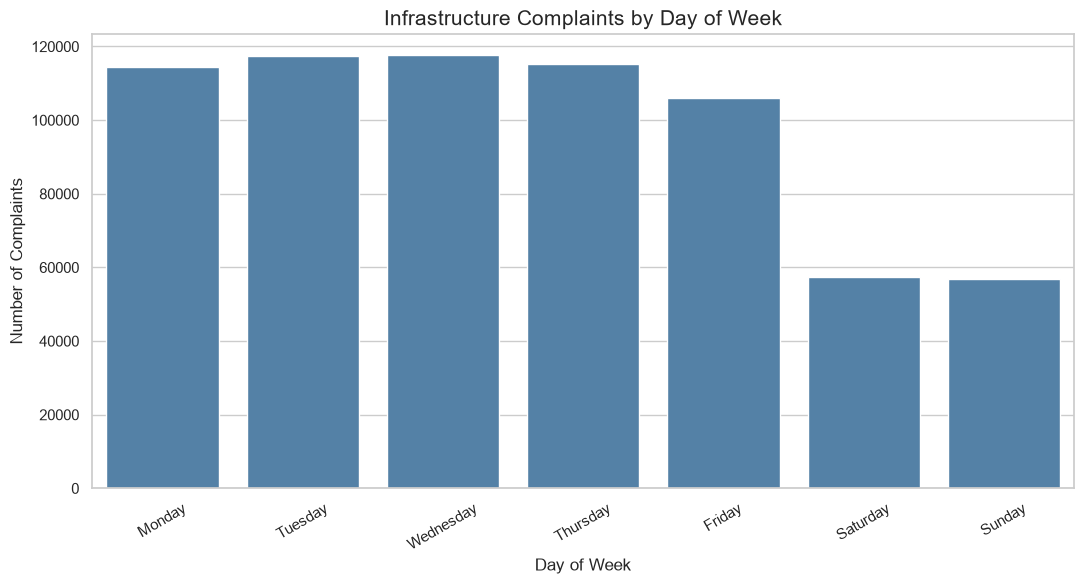

In [34]:
plt.figure(figsize=(11, 6))

sns.barplot(
    color="steelblue",
    data=weekday_summary,
    x="day_name",
    y="complaint_count"
)

plt.title(
    "Infrastructure Complaints by Day of Week",
    fontsize=15
)

plt.xlabel("Day of Week")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "weekday_complaint_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
category_monthly = pd.crosstab(
    df["complaint_type"],
    df["month_name"]
)

category_monthly = category_monthly.reindex(
    columns=month_order
)

display(category_monthly)

month_name,January,February,March,April,May,June,July,August,September,October,November,December
complaint_type,,,,,,,,,,,,
Bridge Condition,80,76,99,49,96,52,88,61,49,37,70,83
Curb Condition,1421,1361,1748,2011,1955,1866,1811,1803,1970,1880,1863,1547
Root/Sewer/Sidewalk Condition,1790,1612,2440,2614,2910,2901,3019,3230,3059,2894,1976,1726
Sewer,6172,4497,6964,6509,7345,6005,7979,8705,8482,8096,5352,6124
Sewer Maintenance,4,5,12,7,11,14,8,9,2224,629,12,14
Sidewalk Condition,4801,4468,5976,6390,6713,6598,6881,7061,6934,7112,5809,5066
Street Condition,17440,17927,22031,19826,20248,19871,17113,16194,14819,13979,11665,14468
Street Light Condition,9562,9252,9834,8683,6528,6263,6830,8087,8664,9610,8215,7731
Street Sign - Damaged,1080,1160,1450,1436,1349,1289,1333,1215,1238,1177,1071,1178


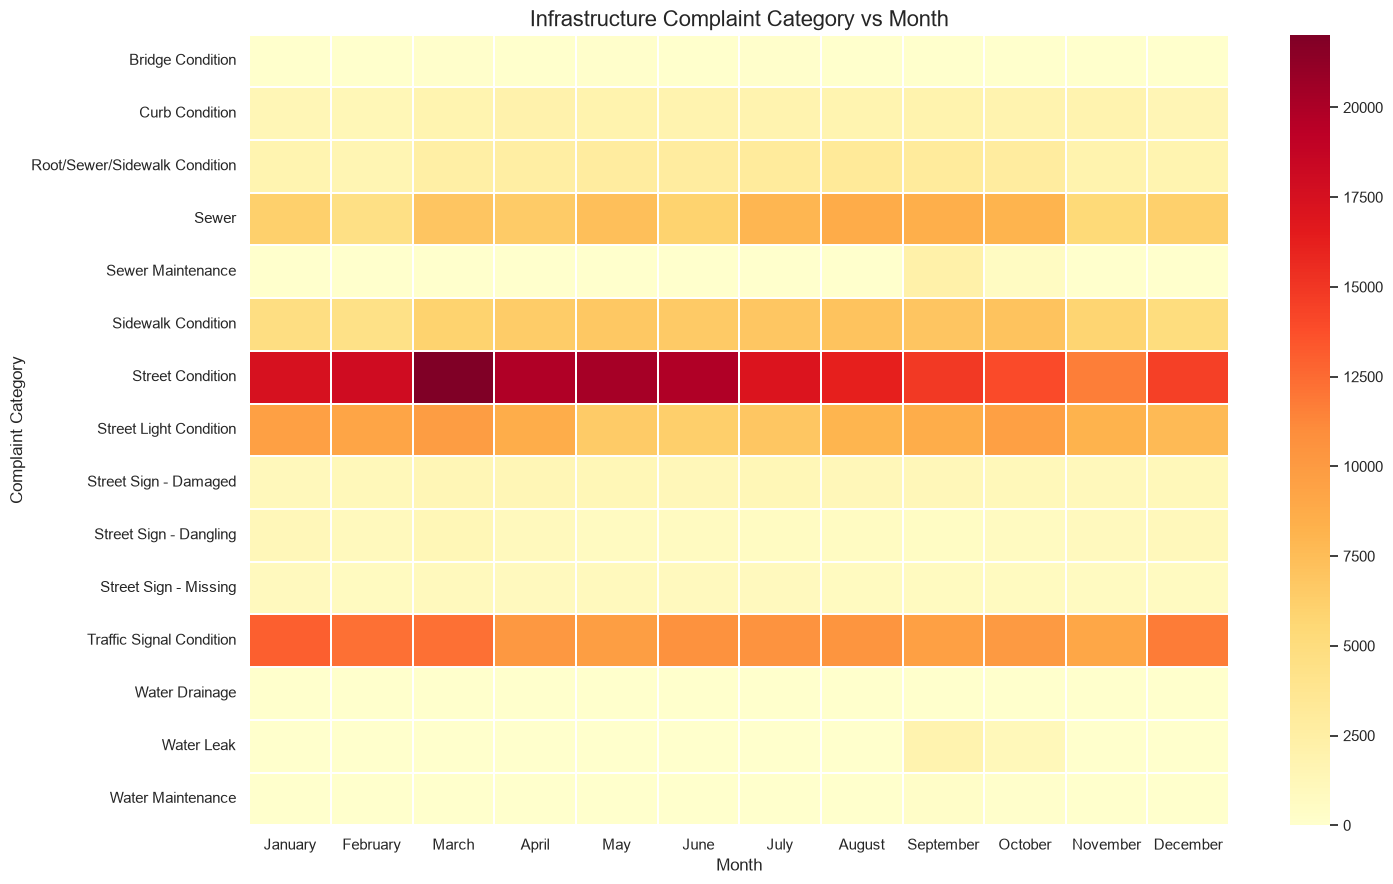

In [36]:
plt.figure(figsize=(15, 9))

sns.heatmap(
    category_monthly,
    cmap="YlOrRd",
    linewidths=0.3,
    annot=False
)

plt.title(
    "Infrastructure Complaint Category vs Month",
    fontsize=16
)

plt.xlabel("Month")
plt.ylabel("Complaint Category")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "category_month_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Section 3 — Temporal interpretation 
Use the newly generated **yearly_summary**, **monthly_summary**, **seasonal_summary**, and **weekday_summary** for this dataset.


### Section 4: Borough-wise Infrastructure Analysis

In [37]:
print("Unique borough values:")
print(df["borough"].value_counts(dropna=False))

print("\nNumber of unique borough values:")
print(df["borough"].nunique(dropna=True))

Unique borough values:
borough
QUEENS           223819
BROOKLYN         209387
MANHATTAN        106534
BRONX             86583
STATEN ISLAND     57245
Unspecified        1716
Name: count, dtype: int64

Number of unique borough values:
6


In [38]:
# Copy only the columns needed here to avoid duplicating the full 53-column dataset.
borough_df = df[["borough", "complaint_type"]].copy()
borough_df["borough_analysis"] = (
    borough_df["borough"].fillna("Missing").astype(str)
    .str.strip().replace("", "Missing")
)
print("Borough analysis dataset:", borough_df.shape)
display(borough_df["borough_analysis"].value_counts()
        .rename_axis("borough").reset_index(name="complaint_count"))


Borough analysis dataset: (685284, 3)


,borough,complaint_count
0,QUEENS,223819
1,BROOKLYN,209387
2,MANHATTAN,106534
3,BRONX,86583
4,STATEN ISLAND,57245
5,Unspecified,1716


In [39]:
borough_summary = (
    borough_df["borough_analysis"]
    .value_counts()
    .reset_index()
)

borough_summary.columns = [
    "borough",
    "complaint_count"
]

borough_summary["percentage"] = (
    borough_summary["complaint_count"]
    / len(borough_df) * 100
).round(2)

display(borough_summary)

,borough,complaint_count,percentage
0,QUEENS,223819,32.66
1,BROOKLYN,209387,30.55
2,MANHATTAN,106534,15.55
3,BRONX,86583,12.63
4,STATEN ISLAND,57245,8.35
5,Unspecified,1716,0.25


In [40]:
borough_summary.to_csv(
    EDA_TABLES_DIR / "borough_complaint_summary.csv",
    index=False
)

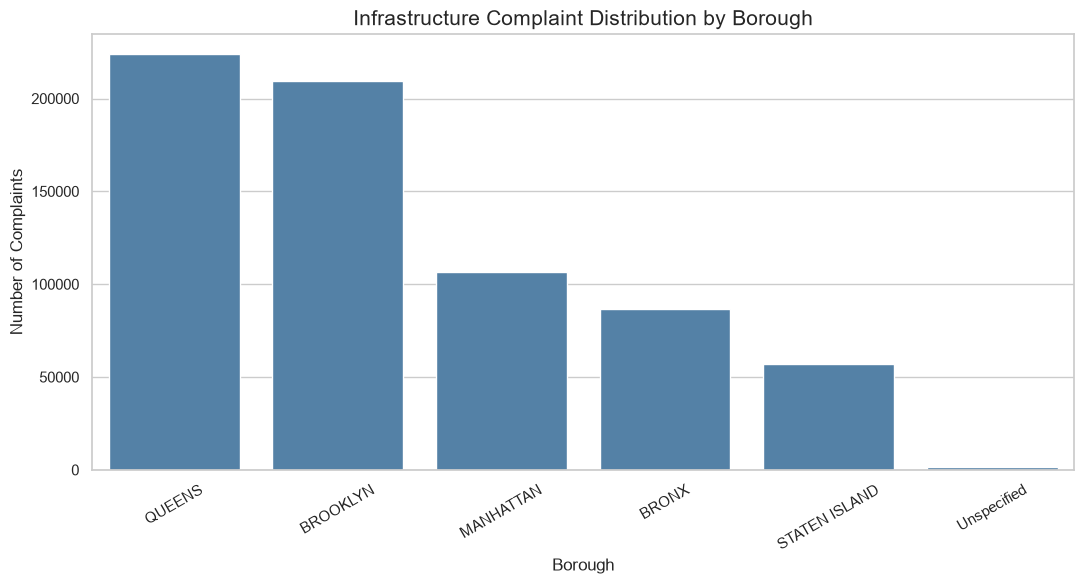

In [41]:
plt.figure(figsize=(11, 6))

sns.barplot(
    color="steelblue",
    data=borough_summary,
    x="borough",
    y="complaint_count"
)

plt.title(
    "Infrastructure Complaint Distribution by Borough",
    fontsize=15
)

plt.xlabel("Borough")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "borough_complaint_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Complaint category distribution within each borough

In [42]:
borough_category = pd.crosstab(
    borough_df["borough_analysis"],
    borough_df["complaint_type"]
)

display(borough_category)

complaint_type,Bridge Condition,Curb Condition,Root/Sewer/Sidewalk Condition,Sewer,Sewer Maintenance,Sidewalk Condition,Street Condition,Street Light Condition,Street Sign - Damaged,Street Sign - Dangling,Street Sign - Missing,Traffic Signal Condition,Water Drainage,Water Leak,Water Maintenance
borough_analysis,,,,,,,,,,,,,,,
BRONX,53,1412,3119,9283,239,7643,21140,19838,1651,1451,1389,18396,31,830,108
BROOKLYN,291,9331,9929,25012,1482,26567,53873,26652,3970,2727,3168,44886,40,1217,242
MANHATTAN,300,3529,755,6192,87,11655,36051,17800,2181,1621,1477,24283,12,556,35
QUEENS,191,5981,11396,33509,952,23072,73839,26048,5945,3682,3580,35013,43,437,131
STATEN ISLAND,5,973,4961,8213,171,4819,20278,8395,1219,1099,789,6276,10,20,17
Unspecified,0,10,11,21,18,53,400,526,10,5,5,636,0,17,4


In [43]:
borough_category.to_csv(
    EDA_TABLES_DIR / "borough_category_counts.csv"
)

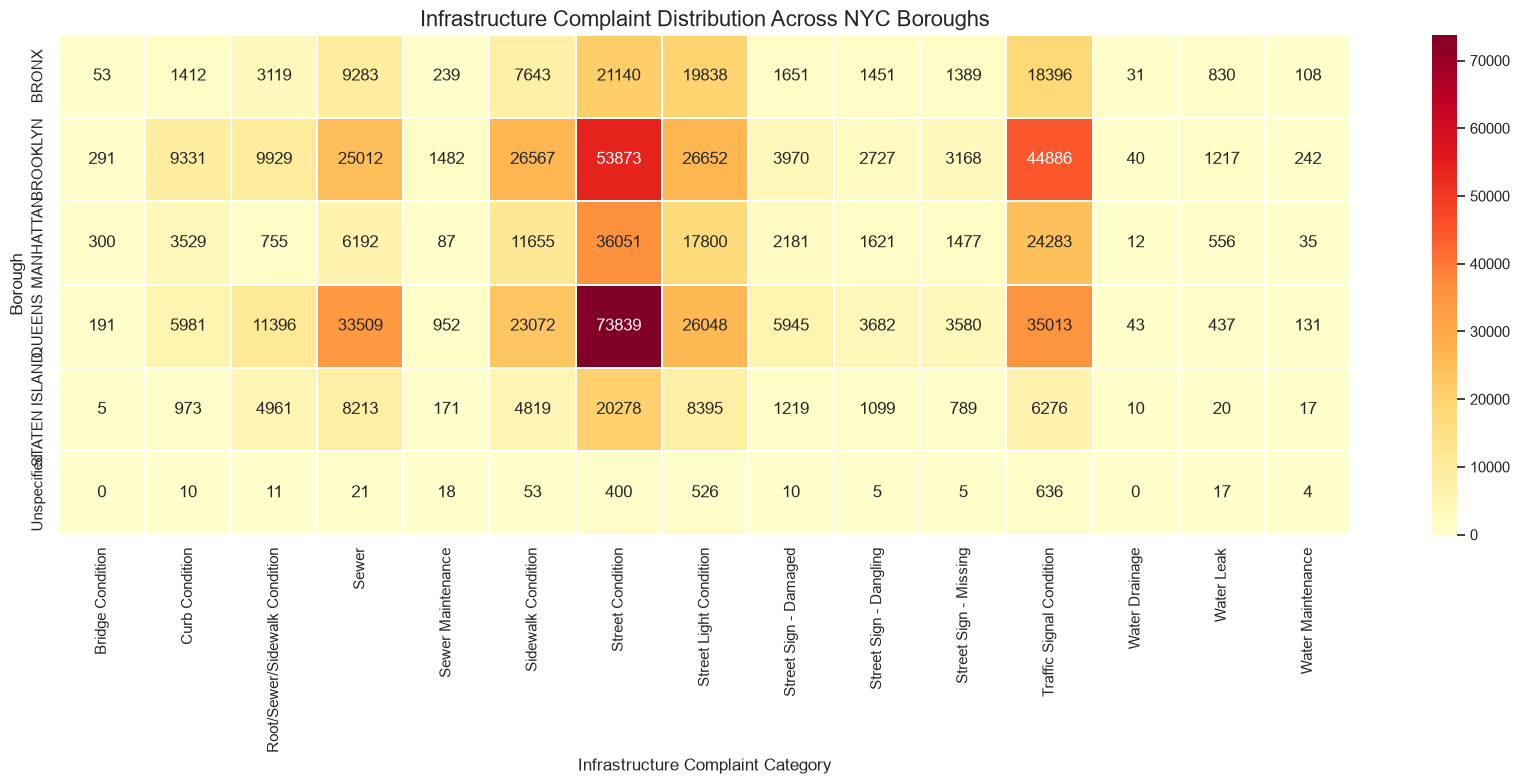

In [44]:
plt.figure(figsize=(17, 8))

sns.heatmap(
    borough_category,
    cmap="YlOrRd",
    linewidths=0.3,
    annot=True,
    fmt="d"
)

plt.title(
    "Infrastructure Complaint Distribution Across NYC Boroughs",
    fontsize=16
)

plt.xlabel("Infrastructure Complaint Category")
plt.ylabel("Borough")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "borough_category_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [45]:
borough_category_percentage = (
    borough_category
    .div(
        borough_category.sum(axis=1),
        axis=0
    ) * 100
)

display(
    borough_category_percentage.round(2)
)

complaint_type,Bridge Condition,Curb Condition,Root/Sewer/Sidewalk Condition,Sewer,Sewer Maintenance,Sidewalk Condition,Street Condition,Street Light Condition,Street Sign - Damaged,Street Sign - Dangling,Street Sign - Missing,Traffic Signal Condition,Water Drainage,Water Leak,Water Maintenance
borough_analysis,,,,,,,,,,,,,,,
BRONX,0.06,1.63,3.60,10.72,0.28,8.83,24.42,22.91,1.91,1.68,1.60,21.25,0.04,0.96,0.12
BROOKLYN,0.14,4.46,4.74,11.95,0.71,12.69,25.73,12.73,1.90,1.30,1.51,21.44,0.02,0.58,0.12
MANHATTAN,0.28,3.31,0.71,5.81,0.08,10.94,33.84,16.71,2.05,1.52,1.39,22.79,0.01,0.52,0.03
QUEENS,0.09,2.67,5.09,14.97,0.43,10.31,32.99,11.64,2.66,1.65,1.60,15.64,0.02,0.20,0.06
STATEN ISLAND,0.01,1.70,8.67,14.35,0.30,8.42,35.42,14.67,2.13,1.92,1.38,10.96,0.02,0.03,0.03
Unspecified,0.00,0.58,0.64,1.22,1.05,3.09,23.31,30.65,0.58,0.29,0.29,37.06,0.00,0.99,0.23


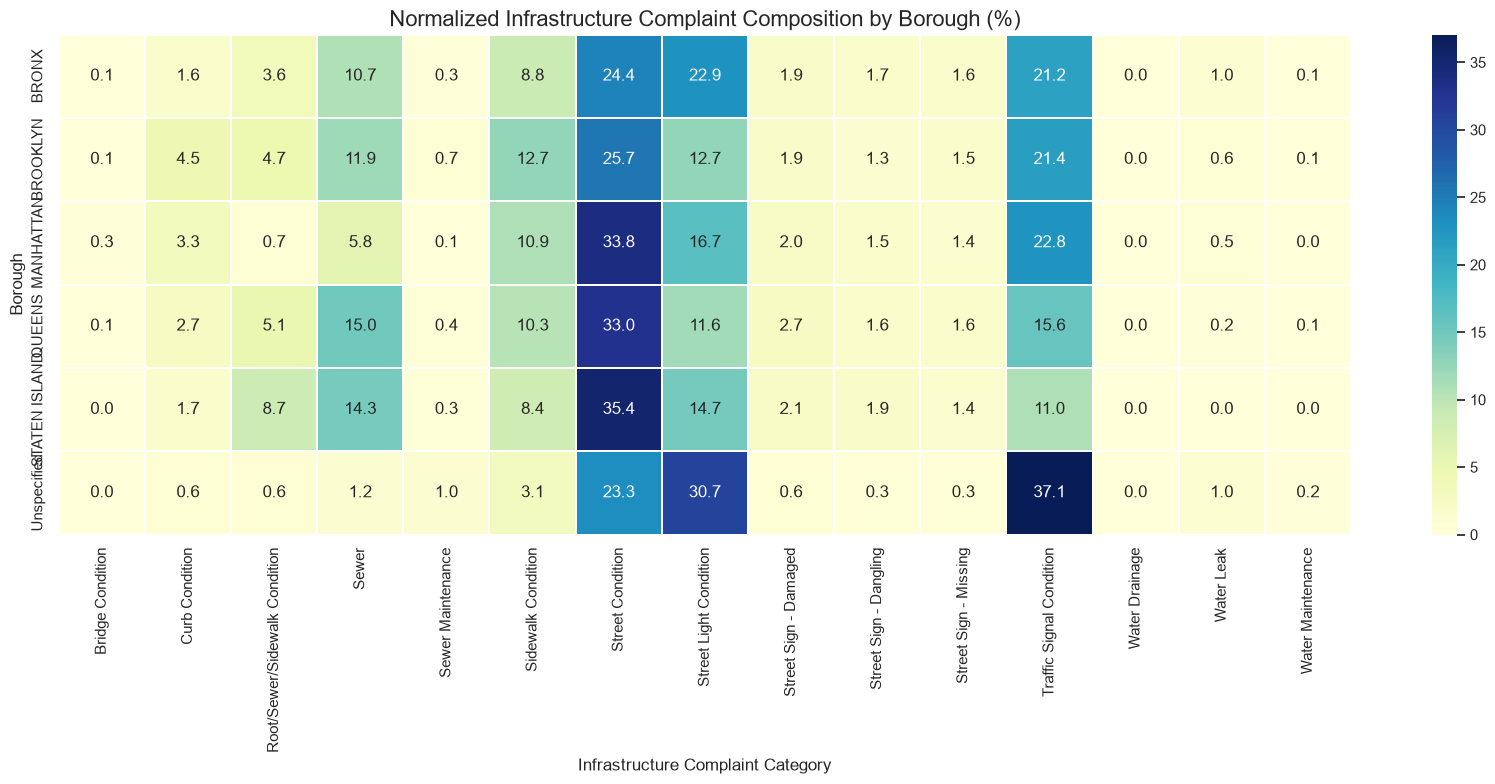

In [46]:
plt.figure(figsize=(17, 8))

sns.heatmap(
    borough_category_percentage,
    cmap="YlGnBu",
    linewidths=0.3,
    annot=True,
    fmt=".1f"
)

plt.title(
    "Normalized Infrastructure Complaint Composition by Borough (%)",
    fontsize=16
)

plt.xlabel("Infrastructure Complaint Category")
plt.ylabel("Borough")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "borough_category_percentage_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Identify the dominant infrastructure category in each borough

In [47]:
dominant_category = pd.DataFrame({
    "dominant_category": borough_category.idxmax(axis=1),
    "complaint_count": borough_category.max(axis=1),
    "percentage": borough_category_percentage.max(axis=1)
})

dominant_category = dominant_category.reset_index()

dominant_category.columns = [
    "borough",
    "dominant_category",
    "complaint_count",
    "percentage"
]

display(dominant_category)

,borough,dominant_category,complaint_count,percentage
0,BRONX,Street Condition,21140,24.42
1,BROOKLYN,Street Condition,53873,25.73
2,MANHATTAN,Street Condition,36051,33.84
3,QUEENS,Street Condition,73839,32.99
4,STATEN ISLAND,Street Condition,20278,35.42
5,Unspecified,Traffic Signal Condition,636,37.06


In [48]:
dominant_category.to_csv(
    EDA_TABLES_DIR / "dominant_category_by_borough.csv",
    index=False
)

In [49]:
nyc_boroughs = [
    "BROOKLYN",
    "QUEENS",
    "MANHATTAN",
    "BRONX",
    "STATEN ISLAND"
]

borough_normalized = (
    borough_df["borough_analysis"]
    .str.upper()
    .str.strip()
)

valid_borough_df = borough_df[
    borough_normalized.isin(nyc_boroughs)
].copy()

print("Total records:", len(borough_df))

print("Records belonging to five official boroughs:",
      len(valid_borough_df))

print("Excluded from five-borough comparison:",
      len(borough_df) - len(valid_borough_df))

Total records: 685284
Records belonging to five official boroughs: 683568
Excluded from five-borough comparison: 1716


Compare category composition across official boroughs

In [50]:
official_borough_category = pd.crosstab(
    valid_borough_df["borough_analysis"].str.title(),
    valid_borough_df["complaint_type"]
)

official_borough_percentage = (
    official_borough_category
    .div(
        official_borough_category.sum(axis=1),
        axis=0
    ) * 100
)

display(official_borough_percentage.round(2))

complaint_type,Bridge Condition,Curb Condition,Root/Sewer/Sidewalk Condition,Sewer,Sewer Maintenance,Sidewalk Condition,Street Condition,Street Light Condition,Street Sign - Damaged,Street Sign - Dangling,Street Sign - Missing,Traffic Signal Condition,Water Drainage,Water Leak,Water Maintenance
borough_analysis,,,,,,,,,,,,,,,
Bronx,0.06,1.63,3.60,10.72,0.28,8.83,24.42,22.91,1.91,1.68,1.60,21.25,0.04,0.96,0.12
Brooklyn,0.14,4.46,4.74,11.95,0.71,12.69,25.73,12.73,1.90,1.30,1.51,21.44,0.02,0.58,0.12
Manhattan,0.28,3.31,0.71,5.81,0.08,10.94,33.84,16.71,2.05,1.52,1.39,22.79,0.01,0.52,0.03
Queens,0.09,2.67,5.09,14.97,0.43,10.31,32.99,11.64,2.66,1.65,1.60,15.64,0.02,0.20,0.06
Staten Island,0.01,1.70,8.67,14.35,0.30,8.42,35.42,14.67,2.13,1.92,1.38,10.96,0.02,0.03,0.03


In [51]:
official_borough_percentage.to_csv(
    EDA_TABLES_DIR / "official_borough_category_composition.csv"
)

### Section 5 — Geographic Distribution Analysis

In [52]:
# Work with the spatial fields only; a full copy of the large source table
# would unnecessarily duplicate hundreds of thousands of text records.
geo_columns = [c for c in ["unique_key", "created_date", "complaint_type",
    "borough", "latitude", "longitude", "incident_zip", "community_board",
    "resolution_hours", "status", "has_valid_coordinates",
    "coordinate_quality_flag"] if c in df.columns]
geo_df = df.loc[:, geo_columns].copy()
geo_df["latitude"] = pd.to_numeric(geo_df["latitude"], errors="coerce")
geo_df["longitude"] = pd.to_numeric(geo_df["longitude"], errors="coerce")
geo_df["has_coordinates"] = (
    geo_df["latitude"].notna() & geo_df["longitude"].notna()
)
print("Total records:", len(geo_df))
print("Records with coordinate pairs:", int(geo_df["has_coordinates"].sum()))
print("Missing coordinate pairs:", int((~geo_df["has_coordinates"]).sum()))


Total records: 685284
Records with coordinate pairs: 611284
Missing coordinate pairs: 74000


In [53]:
# Broad NYC coordinate screening bounds
NYC_LAT_MIN = 40.45
NYC_LAT_MAX = 40.95

NYC_LON_MIN = -74.30
NYC_LON_MAX = -73.65

geo_df["within_nyc_bounds"] = (
    geo_df["latitude"].between(
        NYC_LAT_MIN,
        NYC_LAT_MAX
    )
    &
    geo_df["longitude"].between(
        NYC_LON_MIN,
        NYC_LON_MAX
    )
)

coordinate_summary = pd.DataFrame({
    "Metric": [
        "Total records",
        "Complete coordinate pairs",
        "Missing coordinate pairs",
        "Coordinates within broad NYC bounds",
        "Coordinates outside broad NYC bounds"
    ],
    "Count": [
        len(geo_df),
        int(geo_df["has_coordinates"].sum()),
        int((~geo_df["has_coordinates"]).sum()),
        int(geo_df["within_nyc_bounds"].sum()),
        int(
            (
                geo_df["has_coordinates"]
                & ~geo_df["within_nyc_bounds"]
            ).sum()
        )
    ]
})

coordinate_summary["Percentage"] = (
    coordinate_summary["Count"]
    / len(geo_df) * 100
).round(2)

display(coordinate_summary)

,Metric,Count,Percentage
0,Total records,685284,100.00
1,Complete coordinate pairs,611284,89.20
2,Missing coordinate pairs,74000,10.80
3,Coordinates within broad NYC bounds,611284,89.20
4,Coordinates outside broad NYC bounds,0,0.00


In [54]:
coordinate_summary.to_csv(
    EDA_TABLES_DIR / "coordinate_quality_summary.csv",
    index=False
)

In [55]:
geo_valid = geo_df[
    geo_df["has_coordinates"]
    & geo_df["within_nyc_bounds"]
].copy()

print("Original records:", len(geo_df))

print("Geographically usable records:", len(geo_valid))

print(
    "Usable coordinate percentage:",
    round(len(geo_valid) / len(geo_df) * 100, 2),
    "%"
)

display(
    geo_valid[
        ["latitude", "longitude", "borough", "complaint_type"]
    ].head()
)

Original records: 685284
Geographically usable records: 611284
Usable coordinate percentage: 89.2 %


,latitude,longitude,borough,complaint_type
1,40.68,-73.88,BROOKLYN,Traffic Signal Condition
2,40.76,-73.80,QUEENS,Traffic Signal Condition
3,40.77,-73.92,QUEENS,Traffic Signal Condition
4,40.68,-73.88,BROOKLYN,Traffic Signal Condition
5,40.59,-73.99,BROOKLYN,Traffic Signal Condition


In [56]:
# Save the EDA-ready geographic view ONCE, retaining the fields useful
# for downstream analysis. The raw cleaner also saved a full geographic CSV.
geo_path = PROCESSED_DATA_DIR / "nyc311_geographic_valid.csv"
geo_valid.to_csv(geo_path, index=False)
print(f"Saved {len(geo_valid):,} geographic records to {geo_path}")


Saved 611,284 geographic records to D:\Urban-Infrastructure-Pulse-Intelligence\data\processed\nyc311_geographic_valid.csv


In [57]:
from config.config import (
    EDA_FIGURES_DIR,
    EDA_TABLES_DIR,
    REPORTS_DIR,
    PROCESSED_DATA_DIR
)

In [58]:
PROCESSED_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Processed data directory:", PROCESSED_DATA_DIR)

Processed data directory: D:\Urban-Infrastructure-Pulse-Intelligence\data\processed


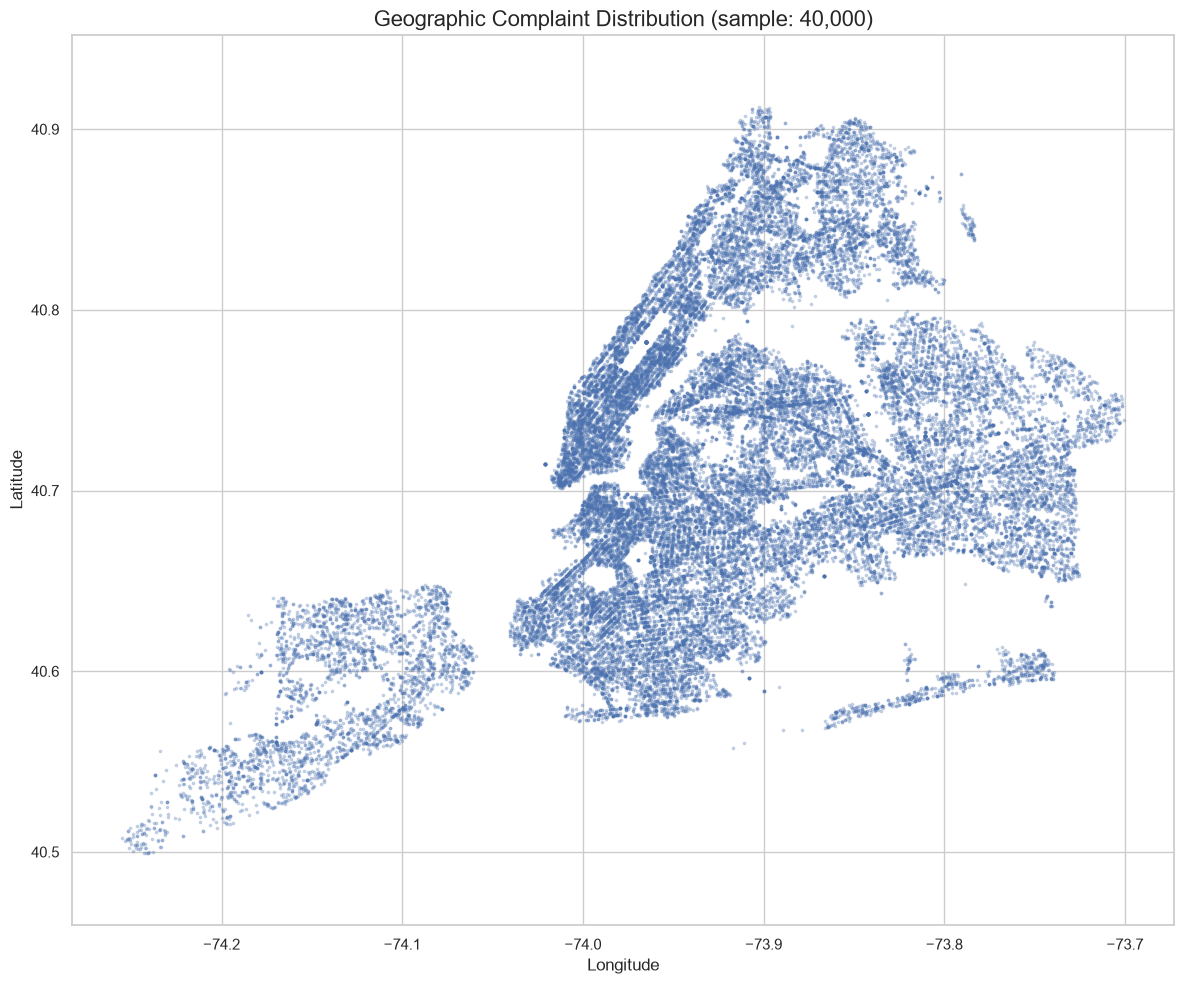

In [62]:
# A representative sample prevents millions of glyphs and oversized image files.
# Hexbin below uses ALL geographically usable records for the density view.
PLOT_SAMPLE_SIZE = 40_000
plot_geo = geo_valid.sample(
    n=min(PLOT_SAMPLE_SIZE, len(geo_valid)), random_state=42
)
plt.figure(figsize=(12, 10))
plt.scatter(plot_geo["longitude"], plot_geo["latitude"], s=3, alpha=0.25)
plt.title(f"Geographic Complaint Distribution (sample: {len(plot_geo):,})", fontsize=16)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.axis("equal")
plt.tight_layout()
plt.savefig(EDA_FIGURES_DIR / "geographic_complaint_distribution.png", dpi=200, bbox_inches="tight")
plt.show()


Borough-wise geographic distribution

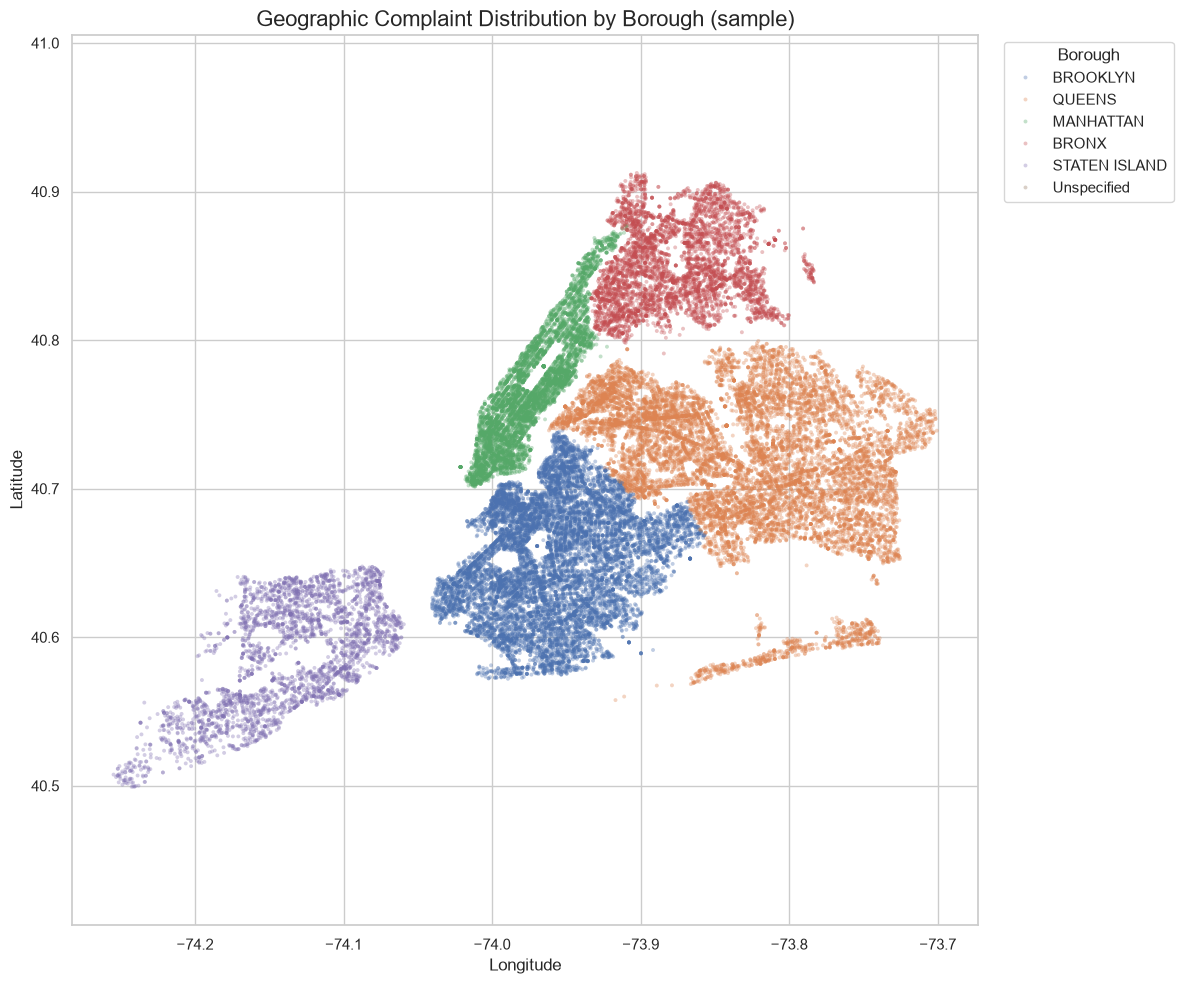

In [63]:
# Borough map is a representative plot sample; not a density estimator.
plt.figure(figsize=(12, 10))
sns.scatterplot(data=plot_geo, x="longitude", y="latitude", hue="borough",
                alpha=0.35, s=8, linewidth=0, rasterized=True)
plt.title("Geographic Complaint Distribution by Borough (sample)", fontsize=16)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Borough", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.axis("equal")
plt.tight_layout()
plt.savefig(EDA_FIGURES_DIR / "geographic_distribution_by_borough.png", dpi=200, bbox_inches="tight")
plt.show()


Spatial Density Analysis

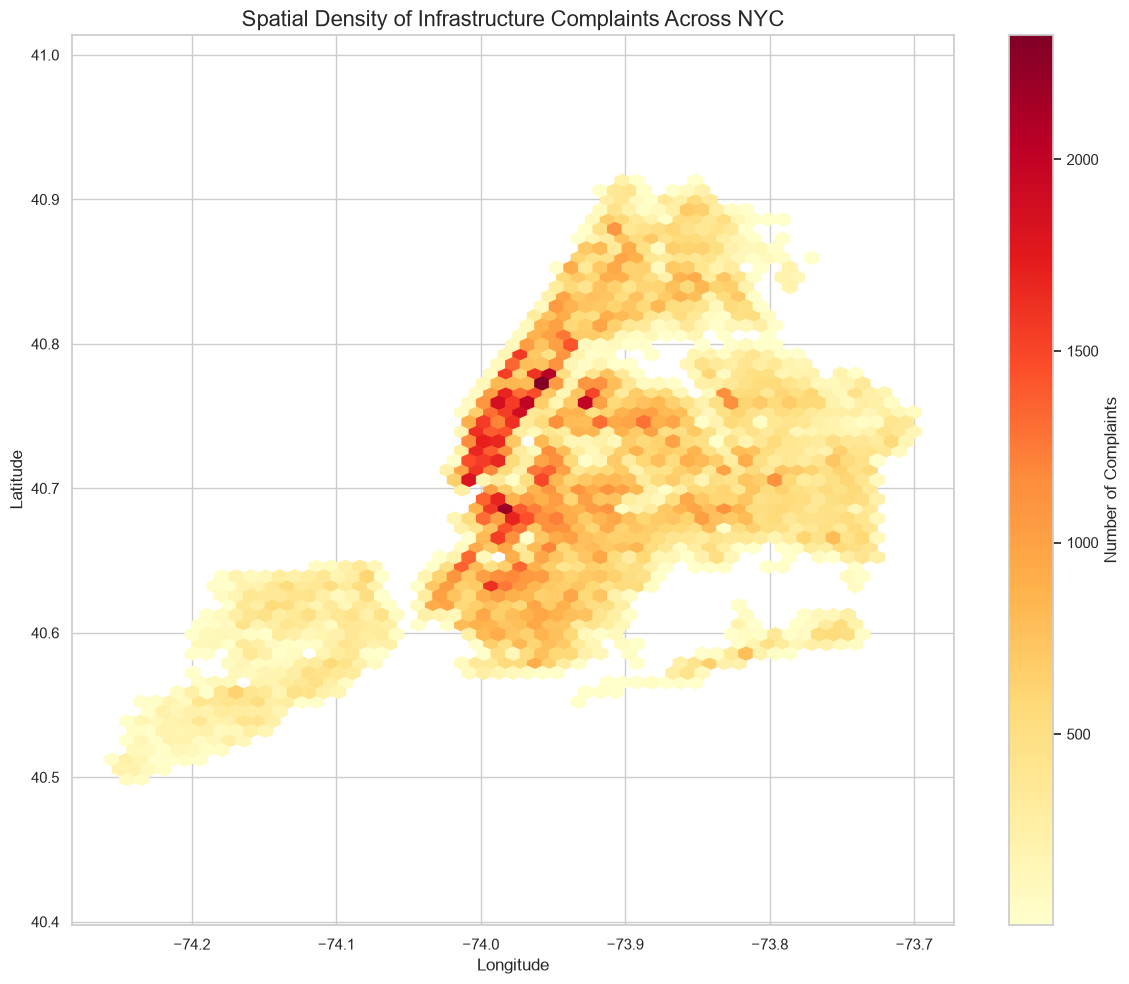

In [64]:
plt.figure(figsize=(12, 10))

density = plt.hexbin(
    geo_valid["longitude"],
    geo_valid["latitude"],
    gridsize=55,
    mincnt=1,
    cmap="YlOrRd"
)

plt.colorbar(
    density,
    label="Number of Complaints"
)

plt.title(
    "Spatial Density of Infrastructure Complaints Across NYC",
    fontsize=16
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.axis("equal")
plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "spatial_complaint_density.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [65]:
top_categories = (
    df["complaint_type"]
    .value_counts()
    .head(5)
    .index
    .tolist()
)

print("Selected categories:")

for category in top_categories:
    print("-", category)

Selected categories:
- Street Condition
- Traffic Signal Condition
- Street Light Condition
- Sewer
- Sidewalk Condition


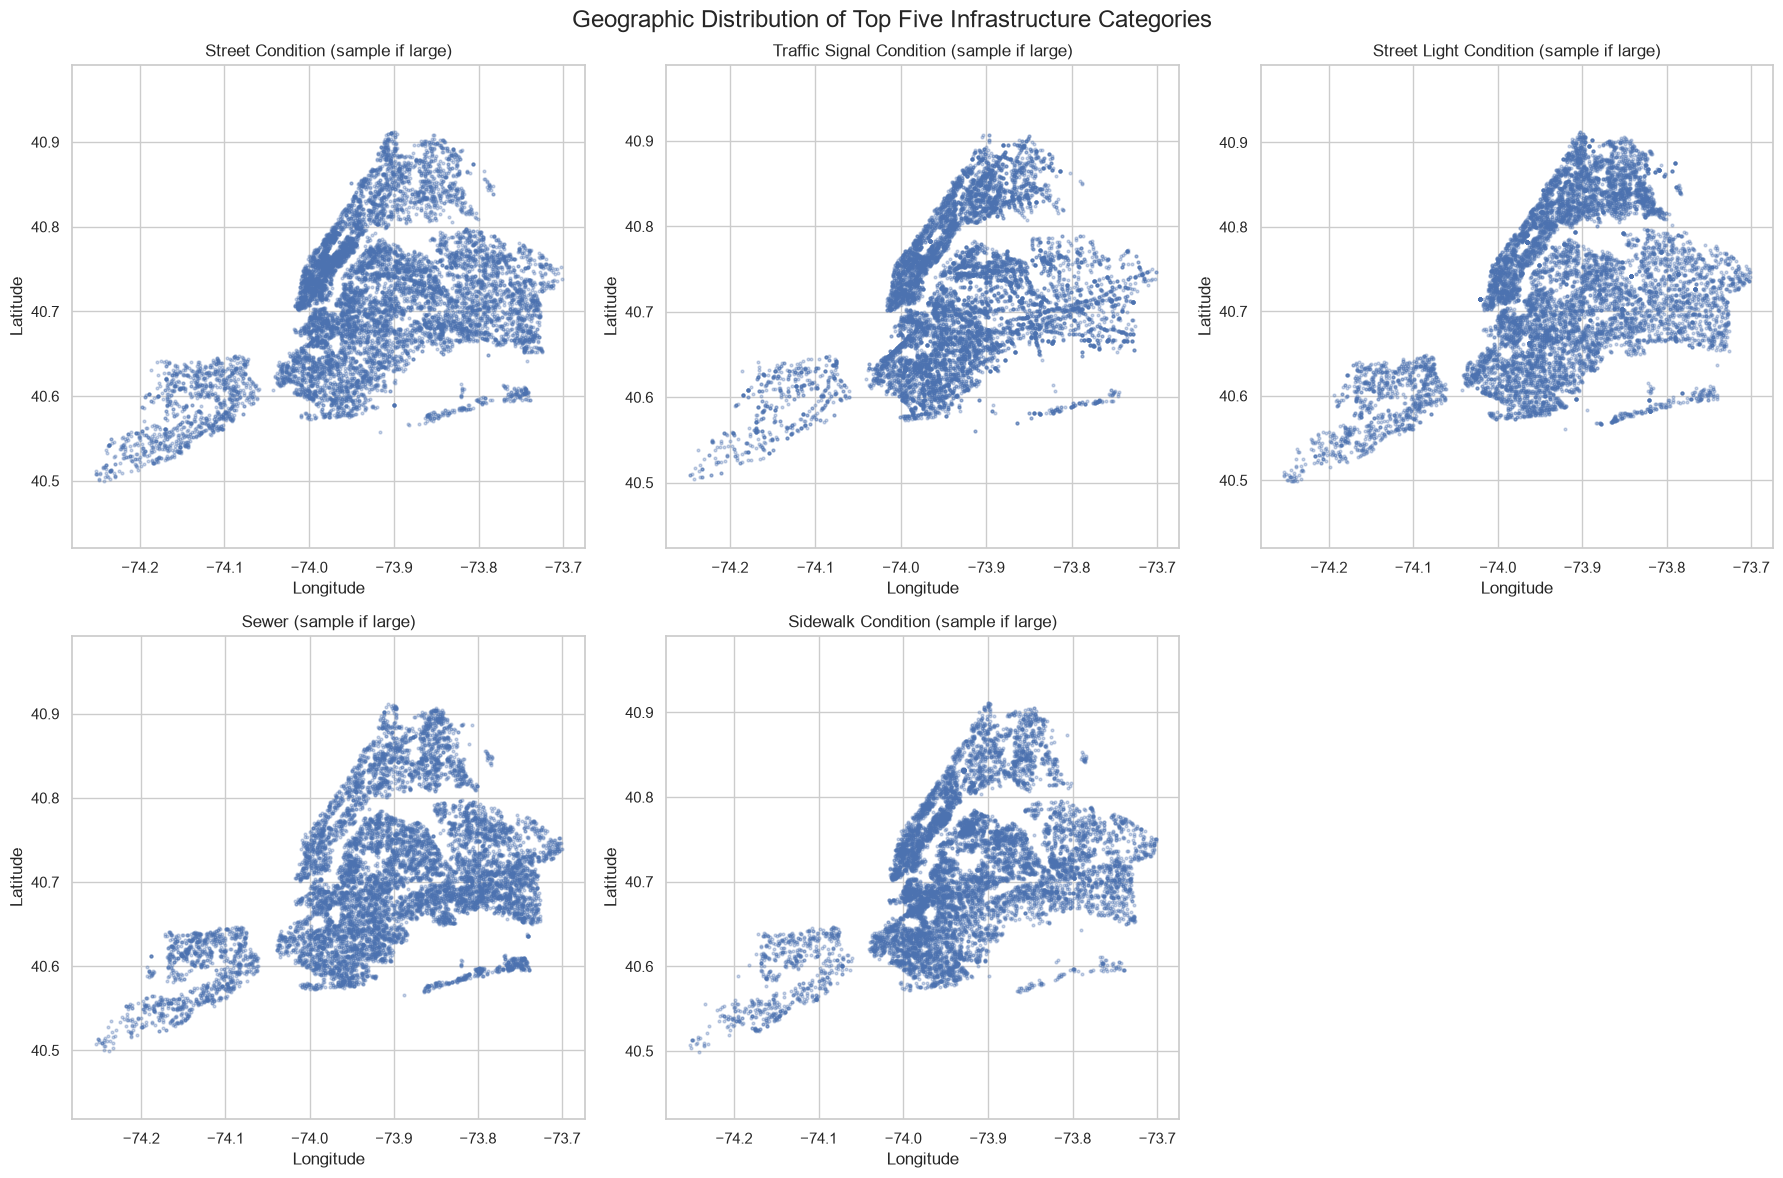

In [66]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
axes = axes.flatten()
for index, category in enumerate(top_categories):
    category_data = geo_valid.loc[
        geo_valid["complaint_type"].eq(category), ["longitude", "latitude"]
    ]
    if len(category_data) > 12_000:
        category_data = category_data.sample(n=12_000, random_state=42)
    axes[index].scatter(category_data["longitude"], category_data["latitude"],
                        s=4, alpha=0.3, rasterized=True)
    axes[index].set_title(category + " (sample if large)")
    axes[index].set_xlabel("Longitude")
    axes[index].set_ylabel("Latitude")
    axes[index].set_aspect("equal", adjustable="datalim")
fig.delaxes(axes[5])
fig.suptitle("Geographic Distribution of Top Five Infrastructure Categories", fontsize=17)
plt.tight_layout()
plt.savefig(EDA_FIGURES_DIR / "top_categories_geographic_distribution.png", dpi=200, bbox_inches="tight")
plt.show()


Geographic Coverage by Borough

In [67]:
borough_coordinate_summary = (
    geo_df.groupby("borough")
    .agg(
        total_records=("unique_key", "count"),
        records_with_coordinates=("has_coordinates", "sum")
    )
)

borough_coordinate_summary["coordinate_percentage"] = (
    borough_coordinate_summary["records_with_coordinates"]
    / borough_coordinate_summary["total_records"]
    * 100
).round(2)

borough_coordinate_summary = (
    borough_coordinate_summary.reset_index()
)

display(borough_coordinate_summary)

,borough,total_records,records_with_coordinates,coordinate_percentage
0,BRONX,86583,76924,88.84
1,BROOKLYN,209387,193196,92.27
2,MANHATTAN,106534,96051,90.16
3,QUEENS,223819,193561,86.48
4,STATEN ISLAND,57245,51244,89.52
5,Unspecified,1716,308,17.95


In [68]:
borough_coordinate_summary.to_csv(
    EDA_TABLES_DIR / "coordinate_availability_by_borough.csv",
    index=False
)

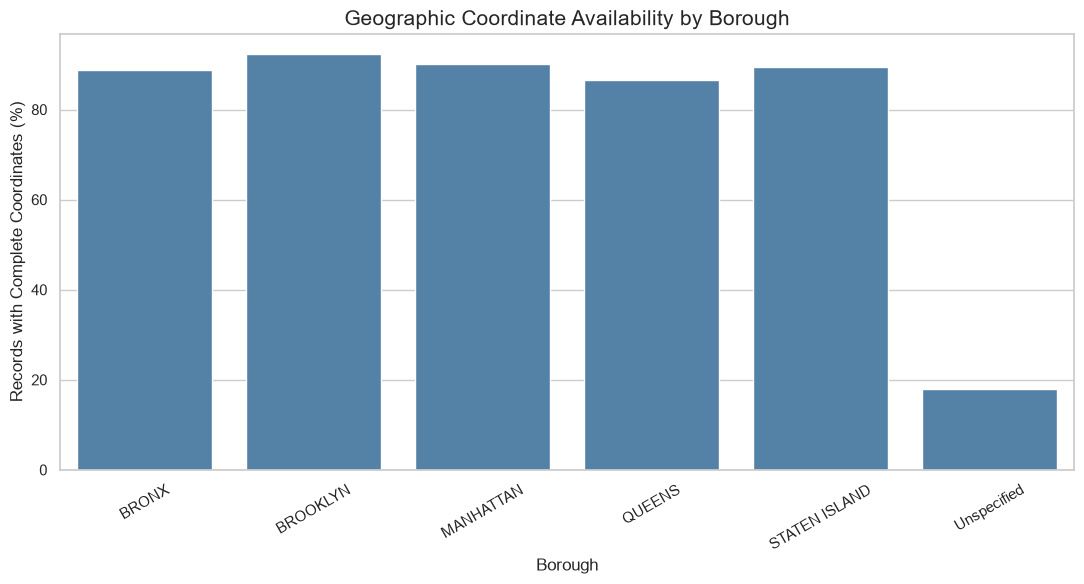

In [69]:
plt.figure(figsize=(11, 6))

sns.barplot(
    color="steelblue",
    data=borough_coordinate_summary,
    x="borough",
    y="coordinate_percentage"
)

plt.title(
    "Geographic Coordinate Availability by Borough",
    fontsize=15
)

plt.xlabel("Borough")
plt.ylabel("Records with Complete Coordinates (%)")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "coordinate_availability_by_borough.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Geographic interpretation 

Refer to **coordinate_summary** for the true count and percentage of records usable for geographic work; the old 100K figure of 89.24% is not applicable here. The plots show reported complaint locations, and the sampled scatter plots are **visual aids**, not spatial hotspot tests. The hexbin density plot uses all valid coordinate pairs but higher absolute counts can also reflect reporting exposure.

Spatial DBSCAN is a later, separate modeling phase; this EDA does not claim that DBSCAN clusters have been identified.


### Section 6 — Resolution-Time Analysis

Prepare resolution-time data

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from config.config import (
    EDA_FIGURES_DIR,
    EDA_TABLES_DIR,
    REPORTS_DIR
)

sns.set_theme(style="whitegrid")

print("Resolution-time analysis initialized.")

Resolution-time analysis initialized.


In [71]:
required_columns = [
    "created_date",
    "closed_date",
    "resolution_hours",
    "complaint_type",
    "borough",
    "status"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

print("All required columns are available.")

All required columns are available.


In [72]:
# Avoid copying all 53 original columns for resolution analysis.
resolution_df = df.loc[:, required_columns].copy()
resolution_df["created_date"] = pd.to_datetime(resolution_df["created_date"], errors="coerce")
resolution_df["closed_date"] = pd.to_datetime(resolution_df["closed_date"], errors="coerce")
resolution_df["resolution_hours"] = pd.to_numeric(resolution_df["resolution_hours"], errors="coerce")
resolution_df["valid_resolution"] = (
    resolution_df["resolution_hours"].notna()
    & (resolution_df["resolution_hours"] >= 0)
    & (resolution_df["closed_date"] >= resolution_df["created_date"])
)
print("Total records:", len(resolution_df))
print("Valid resolution records:", int(resolution_df["valid_resolution"].sum()))
print("Missing or invalid resolution records:", int((~resolution_df["valid_resolution"]).sum()))


Total records: 685284
Valid resolution records: 662118
Missing or invalid resolution records: 23166


In [73]:
valid_resolution_df = resolution_df[
    resolution_df["valid_resolution"]
].copy()

resolution_statistics = (
    valid_resolution_df["resolution_hours"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .to_frame(name="resolution_hours")
)

resolution_statistics["resolution_days"] = (
    resolution_statistics["resolution_hours"] / 24
)

display(resolution_statistics.round(2))

,resolution_hours,resolution_days
count,662118.00,27588.25
mean,401.41,16.73
std,1551.60,64.65
min,0.00,0.00
25%,4.72,0.20
50%,36.25,1.51
75%,171.30,7.14
90%,525.05,21.88
95%,1852.40,77.18
99%,7659.78,319.16


In [74]:
resolution_statistics.to_csv(
    EDA_TABLES_DIR / "resolution_time_statistics.csv"
)

In [75]:
resolution_skewness = (
    valid_resolution_df["resolution_hours"].skew()
)

print("Resolution-time skewness:", round(resolution_skewness, 3))

if resolution_skewness > 1:
    print("Interpretation: Strong positive skewness.")

elif resolution_skewness > 0:
    print("Interpretation: Positive skewness.")

else:
    print("Interpretation: Symmetric or negatively skewed distribution.")

Resolution-time skewness: 7.848
Interpretation: Strong positive skewness.


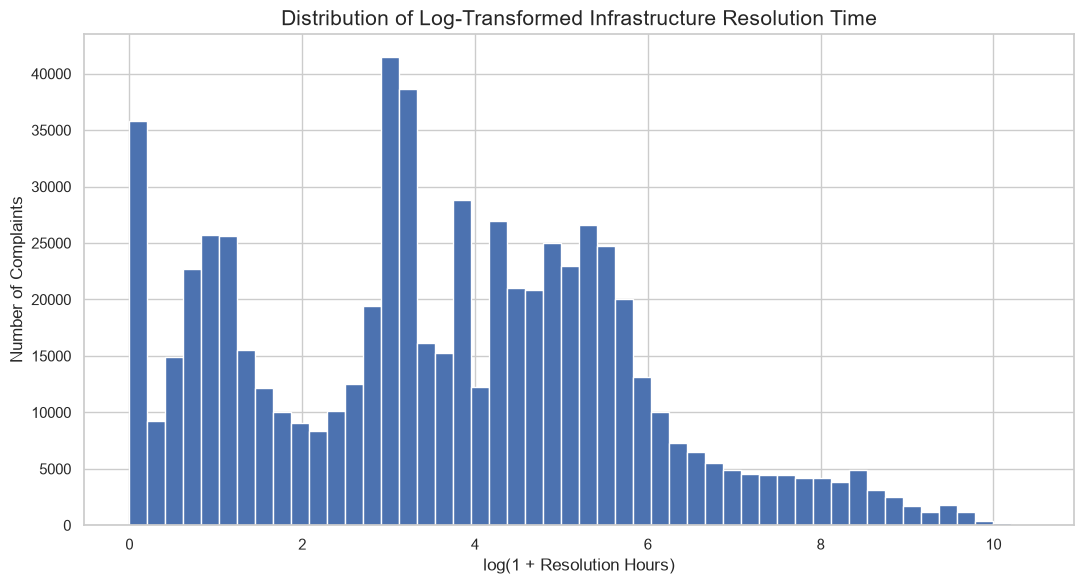

In [76]:
plt.figure(figsize=(11, 6))

plt.hist(
    np.log1p(valid_resolution_df["resolution_hours"]),
    bins=50
)

plt.title(
    "Distribution of Log-Transformed Infrastructure Resolution Time",
    fontsize=15
)

plt.xlabel("log(1 + Resolution Hours)")
plt.ylabel("Number of Complaints")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "resolution_time_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

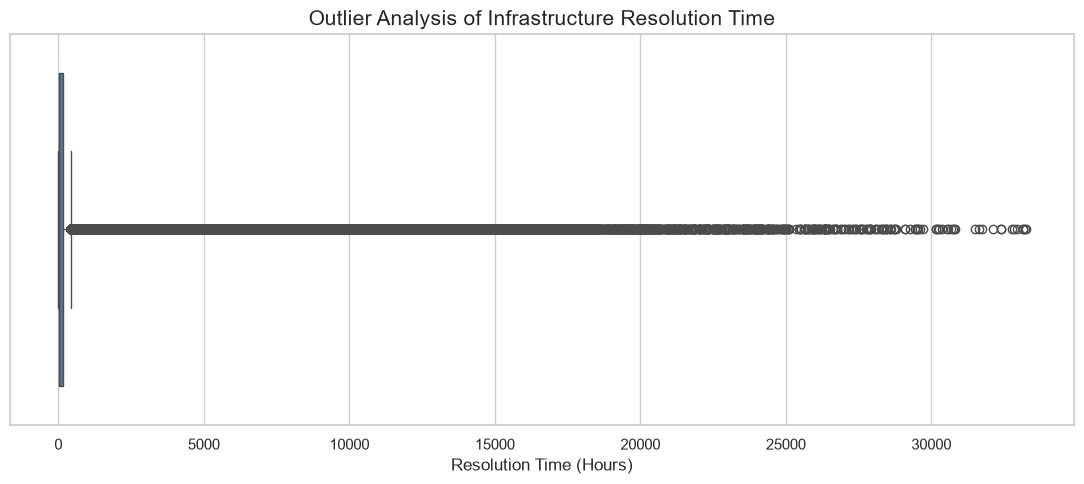

In [77]:
plt.figure(figsize=(11, 5))

sns.boxplot(
    x=valid_resolution_df["resolution_hours"]
)

plt.title(
    "Outlier Analysis of Infrastructure Resolution Time",
    fontsize=15
)

plt.xlabel("Resolution Time (Hours)")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "resolution_time_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Resolution Time by Infrastructure Category

In [78]:
category_resolution = (
    valid_resolution_df
    .groupby("complaint_type")
    .agg(
        complaint_count=("resolution_hours", "count"),
        mean_resolution_hours=("resolution_hours", "mean"),
        median_resolution_hours=("resolution_hours", "median"),
        p90_resolution_hours=(
            "resolution_hours",
            lambda x: x.quantile(0.90)
        )
    )
    .reset_index()
)

category_resolution = category_resolution.sort_values(
    "median_resolution_hours",
    ascending=False
)

display(category_resolution)

,complaint_type,complaint_count,mean_resolution_hours,median_resolution_hours,p90_resolution_hours
2,Root/Sewer/Sidewalk Condition,26472,3390.23,2184.87,7515.83
12,Water Drainage,64,420.60,391.08,948.07
1,Curb Condition,21236,585.60,312.40,1321.14
0,Bridge Condition,840,1030.80,195.19,3815.88
5,Sidewalk Condition,73782,294.43,194.20,511.33
13,Water Leak,2249,238.00,181.73,489.37
7,Street Light Condition,90728,863.88,141.51,1929.17
9,Street Sign - Dangling,10582,247.99,123.13,306.93
10,Street Sign - Missing,10400,758.19,118.64,3164.60
8,Street Sign - Damaged,14968,612.18,116.99,2331.42


In [79]:
category_resolution.to_csv(
    EDA_TABLES_DIR / "category_resolution_statistics.csv",
    index=False
)

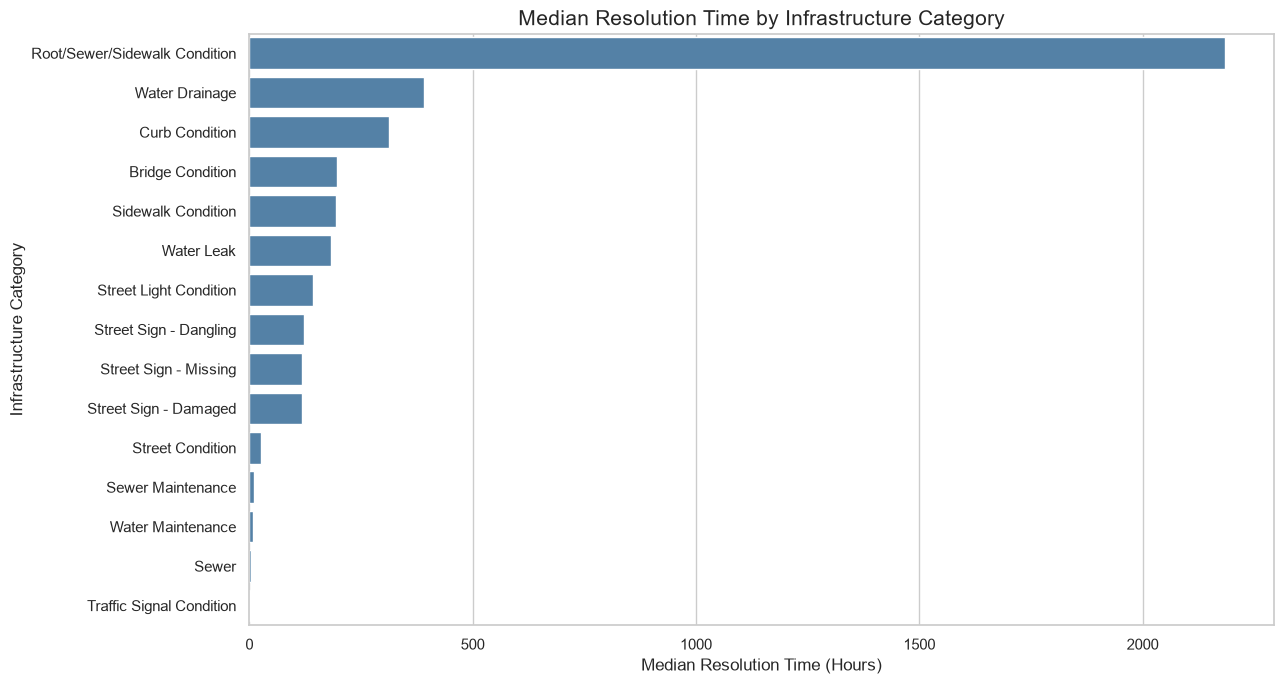

In [80]:
plt.figure(figsize=(13, 7))

sns.barplot(
    color="steelblue",
    data=category_resolution,
    x="median_resolution_hours",
    y="complaint_type"
)

plt.title(
    "Median Resolution Time by Infrastructure Category",
    fontsize=15
)

plt.xlabel("Median Resolution Time (Hours)")
plt.ylabel("Infrastructure Category")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "resolution_time_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Resolution Time by Borough

In [81]:
borough_resolution = (
    valid_resolution_df
    .groupby("borough")
    .agg(
        complaint_count=("resolution_hours", "count"),
        mean_resolution_hours=("resolution_hours", "mean"),
        median_resolution_hours=("resolution_hours", "median"),
        p90_resolution_hours=(
            "resolution_hours",
            lambda x: x.quantile(0.90)
        )
    )
    .reset_index()
)

borough_resolution = borough_resolution.sort_values(
    "median_resolution_hours",
    ascending=False
)

display(borough_resolution)

,borough,complaint_count,mean_resolution_hours,median_resolution_hours,p90_resolution_hours
0,BRONX,83126,377.31,45.98,495.32
1,BROOKLYN,203969,376.21,39.57,541.53
3,QUEENS,214844,449.92,39.56,645.90
4,STATEN ISLAND,55481,530.34,38.07,697.88
2,MANHATTAN,103051,300.21,23.52,332.95
5,Unspecified,1647,399.58,22.40,935.08


In [82]:
borough_resolution.to_csv(
    EDA_TABLES_DIR / "borough_resolution_statistics.csv",
    index=False
)

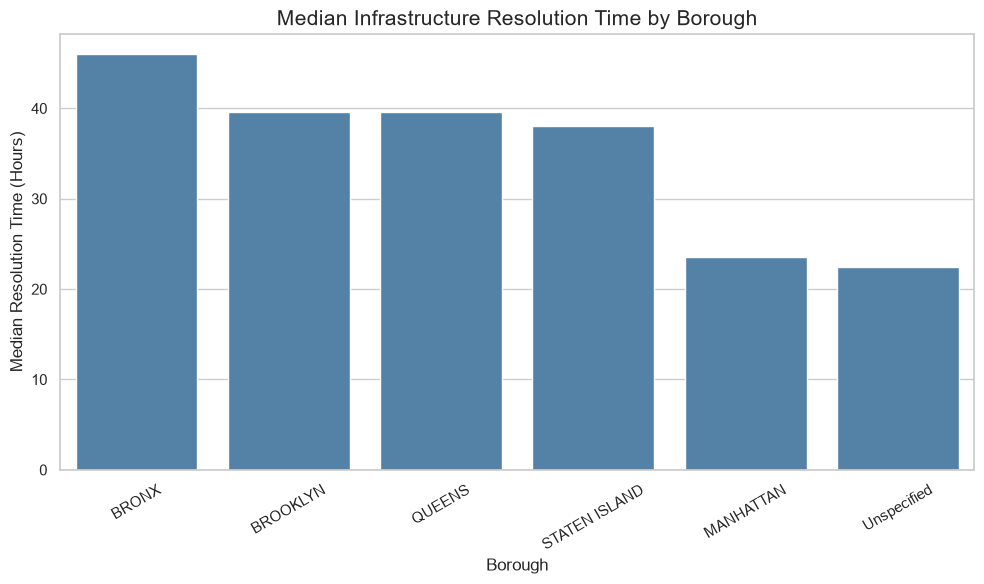

In [83]:
plt.figure(figsize=(10, 6))

sns.barplot(
    color="steelblue",
    data=borough_resolution,
    x="borough",
    y="median_resolution_hours"
)

plt.title(
    "Median Infrastructure Resolution Time by Borough",
    fontsize=15
)

plt.xlabel("Borough")
plt.ylabel("Median Resolution Time (Hours)")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "resolution_time_by_borough.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Open and Closed Complaint Analysis

In [84]:
status_summary = (
    resolution_df["status"]
    .fillna("Missing")
    .value_counts()
    .reset_index()
)

status_summary.columns = [
    "status",
    "complaint_count"
]

status_summary["percentage"] = (
    status_summary["complaint_count"]
    / len(resolution_df) * 100
).round(2)

display(status_summary)

,status,complaint_count,percentage
0,Closed,661133,96.48
1,Pending,12755,1.86
2,In Progress,4685,0.68
3,Assigned,4277,0.62
4,Open,1561,0.23
5,Started,855,0.12
6,Unspecified,18,0.00


In [85]:
status_summary.to_csv(
    EDA_TABLES_DIR / "complaint_status_summary.csv",
    index=False
)

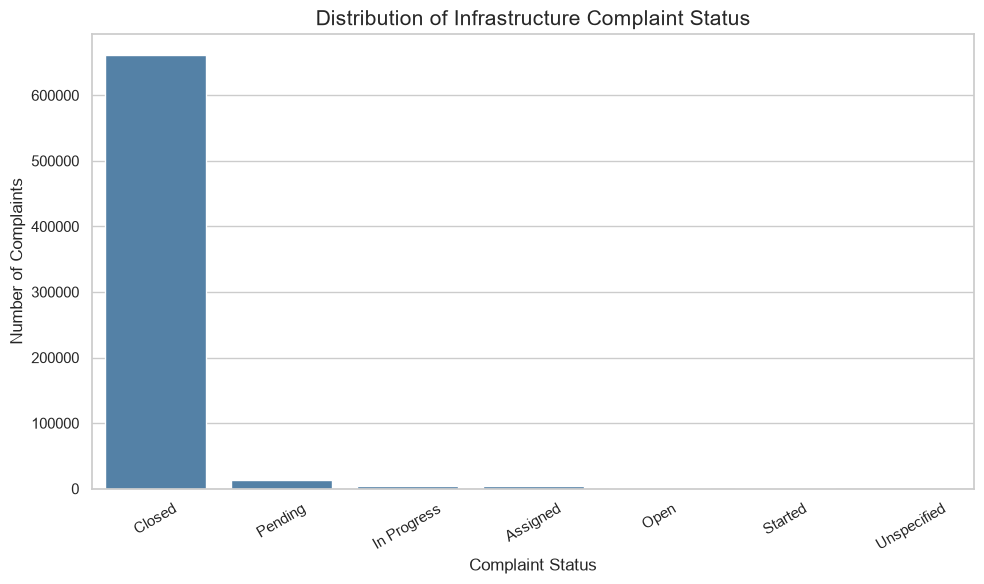

In [86]:
plt.figure(figsize=(10, 6))

sns.barplot(
    color="steelblue",
    data=status_summary,
    x="status",
    y="complaint_count"
)

plt.title(
    "Distribution of Infrastructure Complaint Status",
    fontsize=15
)

plt.xlabel("Complaint Status")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "complaint_status_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Temporal Resolution Analysis

In [87]:
temporal_resolution_df = valid_resolution_df.copy()

temporal_resolution_df["year_month"] = (
    temporal_resolution_df["created_date"]
    .dt.to_period("M")
)

monthly_resolution = (
    temporal_resolution_df
    .groupby("year_month")
    .agg(
        complaint_count=("resolution_hours", "count"),
        median_resolution_hours=("resolution_hours", "median")
    )
    .reset_index()
)

monthly_resolution["year_month"] = (
    monthly_resolution["year_month"].astype(str)
)

display(monthly_resolution.head())

,year_month,complaint_count,median_resolution_hours
0,2023-01,19672,21.86
1,2023-02,17207,21.43
2,2023-03,20828,22.16
3,2023-04,17141,23.33
4,2023-05,17650,35.11


In [88]:
monthly_resolution.to_csv(
    EDA_TABLES_DIR / "monthly_resolution_trends.csv",
    index=False
)

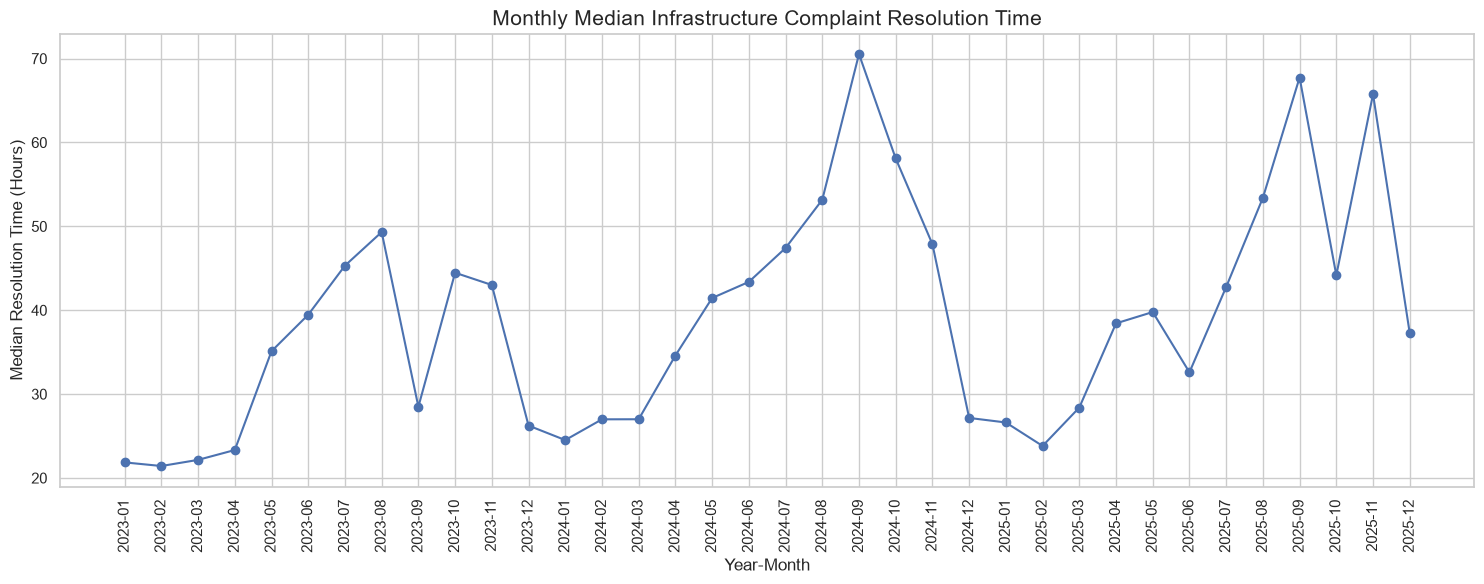

In [89]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly_resolution["year_month"],
    monthly_resolution["median_resolution_hours"],
    marker="o"
)

plt.title(
    "Monthly Median Infrastructure Complaint Resolution Time",
    fontsize=15
)

plt.xlabel("Year-Month")
plt.ylabel("Median Resolution Time (Hours)")

plt.xticks(rotation=90)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "monthly_resolution_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Identify suspicious records

In [90]:
resolution_audit = resolution_df.copy()

resolution_audit["resolution_days"] = (
    resolution_audit["resolution_hours"] / 24
)

# Check timestamp consistency
resolution_audit["closed_before_created"] = (
    resolution_audit["closed_date"]
    < resolution_audit["created_date"]
)

# Classify resolution times
resolution_audit["resolution_flag"] = np.select(
    [
        resolution_audit["resolution_hours"].isna(),
        resolution_audit["resolution_hours"] < 0,
        resolution_audit["resolution_hours"] > 365 * 24,
        resolution_audit["resolution_hours"] > 180 * 24,
        resolution_audit["resolution_hours"] > 90 * 24
    ],
    [
        "Missing",
        "Negative",
        "Above 365 days",
        "Above 180 days",
        "Above 90 days"
    ],
    default="Normal"
)

print(
    resolution_audit["resolution_flag"]
    .value_counts()
)

resolution_flag
Normal            632116
Missing            23166
Above 90 days      14697
Above 180 days      9918
Above 365 days      5387
Name: count, dtype: int64


Inspect extreme complaints

In [91]:
extreme_complaints = (
    resolution_audit[
        resolution_audit["resolution_hours"] > 90 * 24
    ]
    [
        [
            "created_date",
            "closed_date",
            "complaint_type",
            "borough",
            "resolution_hours",
            "resolution_days"
        ]
    ]
    .sort_values(
        "resolution_hours",
        ascending=False
    )
)

display(extreme_complaints.head(20))

,created_date,closed_date,complaint_type,borough,resolution_hours,resolution_days
969,2023-01-03 12:41:50,2026-10-19 12:35:32,Street Condition,BROOKLYN,33239.89,1385.00
1593,2023-01-04 16:34:35,2026-10-19 12:35:32,Street Condition,BROOKLYN,33212.02,1383.83
3423,2023-01-06 14:20:52,2026-10-19 12:35:37,Street Condition,BROOKLYN,33166.25,1381.93
3702,2023-01-06 16:24:29,2026-10-19 12:35:38,Street Condition,BROOKLYN,33164.19,1381.84
9108,2023-01-16 12:25:16,2026-10-19 12:35:53,Street Condition,BROOKLYN,32928.18,1372.01
11396,2023-01-19 13:09:18,2026-10-19 12:35:57,Street Condition,BROOKLYN,32855.44,1368.98
13456,2023-01-22 11:56:54,2026-10-19 12:36:02,Street Condition,BROOKLYN,32784.65,1366.03
8354,2023-01-13 15:39:00,2026-09-24 18:17:00,Street Light Condition,BROOKLYN,32402.63,1350.11
6394,2023-01-11 17:15:00,2026-09-22 16:48:00,Street Light Condition,BROOKLYN,32399.55,1349.98
15284,2023-01-25 10:38:00,2026-09-24 18:12:00,Street Light Condition,BROOKLYN,32119.57,1338.32


Inspect category-level reliability

In [92]:
category_reliability = (
    resolution_audit[
        resolution_audit["valid_resolution"]
    ]
    .groupby("complaint_type")
    .agg(
        valid_records=("resolution_hours", "count"),
        median_hours=("resolution_hours", "median"),
        p90_hours=(
            "resolution_hours",
            lambda x: x.quantile(0.90)
        ),
        maximum_hours=("resolution_hours", "max")
    )
    .reset_index()
)

display(
    category_reliability.sort_values(
        "valid_records",
        ascending=False
    )
)

,complaint_type,valid_records,median_hours,p90_hours,maximum_hours
6,Street Condition,198221,26.42,150.22,33239.89
11,Traffic Signal Condition,129477,2.20,44.83,25713.15
7,Street Light Condition,90728,141.51,1929.17,32402.63
3,Sewer,79669,4.22,110.85,25770.42
5,Sidewalk Condition,73782,194.20,511.33,21281.98
2,Root/Sewer/Sidewalk Condition,26472,2184.87,7515.83,26673.35
1,Curb Condition,21236,312.40,1321.14,18300.59
8,Street Sign - Damaged,14968,116.99,2331.42,16925.90
9,Street Sign - Dangling,10582,123.13,306.93,14417.65
10,Street Sign - Missing,10400,118.64,3164.60,23426.81


Save the audit

In [93]:
category_reliability.to_csv(
    EDA_TABLES_DIR / "resolution_time_reliability.csv",
    index=False
)

extreme_complaints.to_csv(
    EDA_TABLES_DIR / "extreme_resolution_complaints.csv",
    index=False
)

print("Resolution-time audit completed.")

Resolution-time audit completed.


### Phase 7 — Repeated Complaint Analysis

In [94]:
required_columns = ["complaint_type", "borough", "latitude", "longitude", "created_date"]
missing = [col for col in required_columns if col not in geo_valid.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")
# geo_valid is already screened for coordinate ranges. No need to re-scan
# the full master dataset or re-copy its many textual columns.
repeat_df = geo_valid[required_columns].copy()
repeat_df["created_date"] = pd.to_datetime(repeat_df["created_date"], errors="coerce")
repeat_df = repeat_df.dropna(subset=required_columns)
repeat_df["report_day"] = repeat_df["created_date"].dt.normalize()
print("Valid records:", len(repeat_df))
print("Unique complaint categories:", repeat_df["complaint_type"].nunique())
print("Unique boroughs:", repeat_df["borough"].nunique())
print("Caution: nearby reports may refer to different incidents or to duplicate reports of one incident.")


Valid records: 611284
Unique complaint categories: 15
Unique boroughs: 6
Caution: nearby reports may refer to different incidents or to duplicate reports of one incident.


In [95]:
repeat_df["latitude_rounded"] = (
    repeat_df["latitude"].round(4)
)

repeat_df["longitude_rounded"] = (
    repeat_df["longitude"].round(4)
)

location_columns = [
    "complaint_type",
    "borough",
    "latitude_rounded",
    "longitude_rounded"
]

print(repeat_df.head())

             complaint_type   borough  latitude  longitude  \
1  Traffic Signal Condition  BROOKLYN     40.68     -73.88   
2  Traffic Signal Condition    QUEENS     40.76     -73.80   
3  Traffic Signal Condition    QUEENS     40.77     -73.92   
4  Traffic Signal Condition  BROOKLYN     40.68     -73.88   
5  Traffic Signal Condition  BROOKLYN     40.59     -73.99   

         created_date report_day  latitude_rounded  longitude_rounded  
1 2023-01-01 00:18:00 2023-01-01             40.68             -73.88  
2 2023-01-01 00:25:00 2023-01-01             40.76             -73.80  
3 2023-01-01 00:52:00 2023-01-01             40.77             -73.92  
4 2023-01-01 00:18:00 2023-01-01             40.68             -73.88  
5 2023-01-01 00:21:00 2023-01-01             40.59             -73.99  


In [96]:
repeated_locations = (
    repeat_df.groupby(location_columns, observed=True)
    .agg(
        complaint_count=("created_date", "size"),
        first_reported=("created_date", "min"),
        last_reported=("created_date", "max"),
        unique_report_dates=("report_day", "nunique")
    )
    .reset_index()
    .sort_values("complaint_count", ascending=False)
)
print("Total rounded-coordinate/category groups:", len(repeated_locations))
print("Groups with >1 report:", int((repeated_locations["complaint_count"] > 1).sum()))
display(repeated_locations.head(20))


Total rounded-coordinate/category groups: 272207
Groups with >1 report: 100927


,complaint_type,borough,latitude_rounded,longitude_rounded,complaint_count,first_reported,last_reported,unique_report_dates
212234,Street Light Condition,MANHATTAN,40.78,-73.97,598,2023-01-01 19:07:00,2025-12-23 11:04:00,303
220331,Street Light Condition,QUEENS,40.74,-73.84,418,2023-01-03 10:30:00,2025-12-29 14:03:00,174
253770,Street Sign - Missing,QUEENS,40.73,-73.81,329,2023-03-19 12:16:14,2024-10-22 12:40:47,288
205970,Street Light Condition,BROOKLYN,40.66,-73.96,226,2023-01-04 15:57:00,2025-11-15 23:45:00,122
209456,Street Light Condition,MANHATTAN,40.71,-74.02,220,2023-01-05 17:20:00,2025-12-31 11:58:00,179
268276,Traffic Signal Condition,QUEENS,40.77,-73.92,194,2023-01-04 21:05:00,2025-11-08 01:00:00,86
217305,Street Light Condition,QUEENS,40.70,-73.85,192,2023-01-24 21:29:00,2025-11-23 22:53:00,87
265893,Traffic Signal Condition,QUEENS,40.69,-73.85,170,2023-01-03 11:09:00,2025-12-31 13:46:00,81
264103,Traffic Signal Condition,MANHATTAN,40.78,-73.97,154,2023-01-01 08:47:00,2025-12-24 07:35:00,127
219110,Street Light Condition,QUEENS,40.73,-73.77,153,2023-02-27 11:34:00,2025-12-22 11:12:00,82


In [97]:
total_groups = len(repeated_locations)

repeated_groups = (
    repeated_locations["complaint_count"] > 1
).sum()

repeat_percentage = (
    repeated_groups / total_groups * 100
    if total_groups > 0 else 0
)

print("Total location-category groups:", total_groups)
print("Repeated groups:", repeated_groups)

print(
    f"Repeated location percentage: "
    f"{repeat_percentage:.2f}%"
)

Total location-category groups: 272207
Repeated groups: 100927
Repeated location percentage: 37.08%


In [98]:
category_repeats = (
    repeated_locations
    .groupby("complaint_type")
    .agg(
        total_locations=("complaint_count", "count"),
        repeated_locations=(
            "complaint_count",
            lambda x: (x > 1).sum()
        ),
        total_complaints=("complaint_count", "sum"),
        average_complaints=("complaint_count", "mean"),
        maximum_complaints=("complaint_count", "max")
    )
    .reset_index()
)

category_repeats["repeat_rate_percentage"] = (
    category_repeats["repeated_locations"]
    / category_repeats["total_locations"]
    * 100
)

category_repeats = category_repeats.sort_values(
    "repeat_rate_percentage",
    ascending=False
)

display(category_repeats)

,complaint_type,total_locations,repeated_locations,total_complaints,average_complaints,maximum_complaints,repeat_rate_percentage
11,Traffic Signal Condition,13613,12218,120744,8.87,194,89.75
7,Street Light Condition,30190,17869,93622,3.10,598,59.19
6,Street Condition,67117,26546,148388,2.21,96,39.55
3,Sewer,46803,15781,81463,1.74,53,33.72
5,Sidewalk Condition,44219,14240,73468,1.66,85,32.20
2,Root/Sewer/Sidewalk Condition,20051,5957,30141,1.50,29,29.71
13,Water Leak,2323,509,3071,1.32,15,21.91
1,Curb Condition,15908,3238,21222,1.33,49,20.35
0,Bridge Condition,6,1,7,1.17,2,16.67
10,Street Sign - Missing,8037,1181,10298,1.28,329,14.69


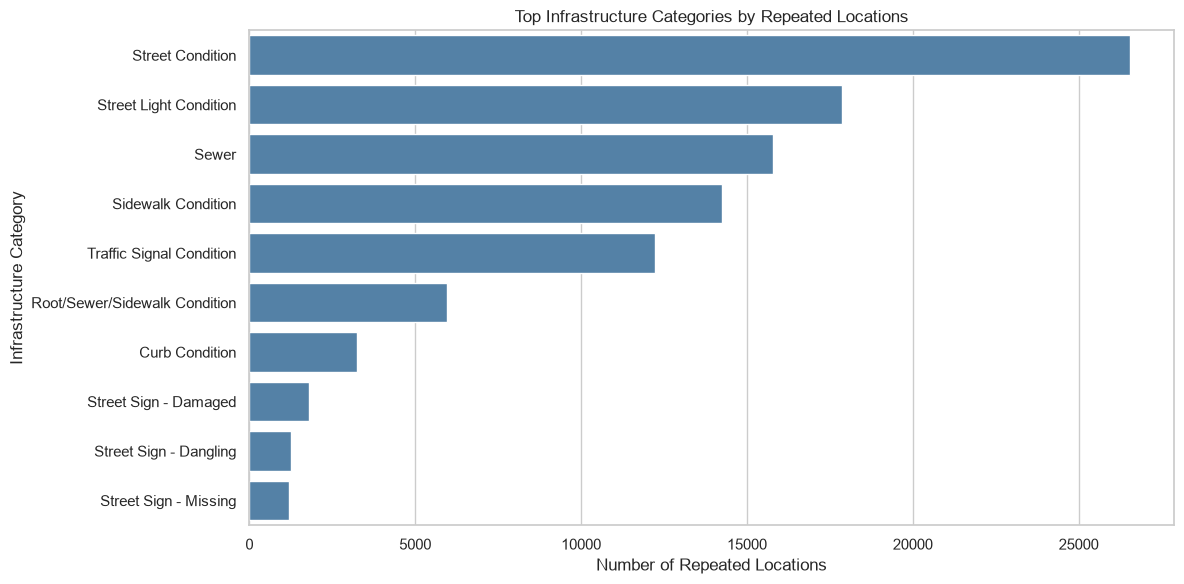

In [99]:
top_categories = (
    category_repeats
    .sort_values(
        "repeated_locations",
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    color="steelblue",
    data=top_categories,
    x="repeated_locations",
    y="complaint_type"
)

plt.title("Top Infrastructure Categories by Repeated Locations")
plt.xlabel("Number of Repeated Locations")
plt.ylabel("Infrastructure Category")

plt.tight_layout()
plt.show()

In [100]:
high_recurrence_locations = (
    repeated_locations[
        repeated_locations["complaint_count"] >= 5
    ]
    .copy()
)

high_recurrence_locations = (
    high_recurrence_locations.sort_values(
        "complaint_count",
        ascending=False
    )
)

print(
    "Locations with at least 5 complaints:",
    len(high_recurrence_locations)
)

display(high_recurrence_locations.head(25))

Locations with at least 5 complaints: 24985


,complaint_type,borough,latitude_rounded,longitude_rounded,complaint_count,first_reported,last_reported,unique_report_dates
212234,Street Light Condition,MANHATTAN,40.78,-73.97,598,2023-01-01 19:07:00,2025-12-23 11:04:00,303
220331,Street Light Condition,QUEENS,40.74,-73.84,418,2023-01-03 10:30:00,2025-12-29 14:03:00,174
253770,Street Sign - Missing,QUEENS,40.73,-73.81,329,2023-03-19 12:16:14,2024-10-22 12:40:47,288
205970,Street Light Condition,BROOKLYN,40.66,-73.96,226,2023-01-04 15:57:00,2025-11-15 23:45:00,122
209456,Street Light Condition,MANHATTAN,40.71,-74.02,220,2023-01-05 17:20:00,2025-12-31 11:58:00,179
268276,Traffic Signal Condition,QUEENS,40.77,-73.92,194,2023-01-04 21:05:00,2025-11-08 01:00:00,86
217305,Street Light Condition,QUEENS,40.70,-73.85,192,2023-01-24 21:29:00,2025-11-23 22:53:00,87
265893,Traffic Signal Condition,QUEENS,40.69,-73.85,170,2023-01-03 11:09:00,2025-12-31 13:46:00,81
264103,Traffic Signal Condition,MANHATTAN,40.78,-73.97,154,2023-01-01 08:47:00,2025-12-24 07:35:00,127
219110,Street Light Condition,QUEENS,40.73,-73.77,153,2023-02-27 11:34:00,2025-12-22 11:12:00,82


In [101]:
repeated_locations.to_csv(
    EDA_TABLES_DIR / "repeated_complaint_locations.csv",
    index=False
)

category_repeats.to_csv(
    EDA_TABLES_DIR / "category_repeat_statistics.csv",
    index=False
)

high_recurrence_locations.to_csv(
    EDA_TABLES_DIR / "high_recurrence_locations.csv",
    index=False
)

print("Repeated complaint analysis completed.")

Repeated complaint analysis completed.


In [102]:
repeated_locations["recurrence_days"] = (
    repeated_locations["last_reported"]
    - repeated_locations["first_reported"]
).dt.days

repeated_locations["recurrence_months"] = (
    repeated_locations["recurrence_days"] / 30.44
)

display(
    repeated_locations.sort_values(
        "recurrence_days",
        ascending=False
    ).head(20)
)

,complaint_type,borough,latitude_rounded,longitude_rounded,complaint_count,first_reported,last_reported,unique_report_dates,recurrence_days,recurrence_months
191614,Street Condition,STATEN ISLAND,40.56,-74.20,51,2023-01-02 09:19:22,2025-12-31 14:13:04,40,1094,35.94
259549,Traffic Signal Condition,BROOKLYN,40.64,-74.02,17,2023-01-02 11:40:00,2025-12-31 01:35:00,15,1093,35.91
265893,Traffic Signal Condition,QUEENS,40.69,-73.85,170,2023-01-03 11:09:00,2025-12-31 13:46:00,81,1093,35.91
209426,Street Light Condition,MANHATTAN,40.71,-74.00,9,2023-01-01 11:12:00,2025-12-29 17:16:00,7,1093,35.91
268093,Traffic Signal Condition,QUEENS,40.76,-73.92,24,2023-01-02 11:19:00,2025-12-30 14:09:00,23,1093,35.91
256283,Traffic Signal Condition,BRONX,40.83,-73.86,27,2023-01-01 21:43:00,2025-12-29 03:04:00,22,1092,35.87
164256,Street Condition,MANHATTAN,40.78,-73.96,25,2023-01-04 08:16:28,2025-12-31 15:39:52,23,1092,35.87
267600,Traffic Signal Condition,QUEENS,40.75,-73.83,12,2023-01-02 09:26:00,2025-12-29 13:53:00,9,1092,35.87
264788,Traffic Signal Condition,MANHATTAN,40.82,-73.94,17,2023-01-03 10:11:00,2025-12-30 22:30:00,12,1092,35.87
265769,Traffic Signal Condition,QUEENS,40.69,-73.83,22,2023-01-02 15:17:00,2025-12-30 08:56:00,12,1092,35.87


In [103]:
persistent_locations = repeated_locations[
    (repeated_locations["complaint_count"] >= 5) &
    (repeated_locations["recurrence_days"] >= 90)
].copy()

print(
    "Persistent complaint locations:",
    len(persistent_locations)
)

display(
    persistent_locations.sort_values(
        "complaint_count",
        ascending=False
    ).head(20)
)

Persistent complaint locations: 23659


,complaint_type,borough,latitude_rounded,longitude_rounded,complaint_count,first_reported,last_reported,unique_report_dates,recurrence_days,recurrence_months
212234,Street Light Condition,MANHATTAN,40.78,-73.97,598,2023-01-01 19:07:00,2025-12-23 11:04:00,303,1086,35.68
220331,Street Light Condition,QUEENS,40.74,-73.84,418,2023-01-03 10:30:00,2025-12-29 14:03:00,174,1091,35.84
253770,Street Sign - Missing,QUEENS,40.73,-73.81,329,2023-03-19 12:16:14,2024-10-22 12:40:47,288,583,19.15
205970,Street Light Condition,BROOKLYN,40.66,-73.96,226,2023-01-04 15:57:00,2025-11-15 23:45:00,122,1046,34.36
209456,Street Light Condition,MANHATTAN,40.71,-74.02,220,2023-01-05 17:20:00,2025-12-31 11:58:00,179,1090,35.81
268276,Traffic Signal Condition,QUEENS,40.77,-73.92,194,2023-01-04 21:05:00,2025-11-08 01:00:00,86,1038,34.10
217305,Street Light Condition,QUEENS,40.70,-73.85,192,2023-01-24 21:29:00,2025-11-23 22:53:00,87,1034,33.97
265893,Traffic Signal Condition,QUEENS,40.69,-73.85,170,2023-01-03 11:09:00,2025-12-31 13:46:00,81,1093,35.91
264103,Traffic Signal Condition,MANHATTAN,40.78,-73.97,154,2023-01-01 08:47:00,2025-12-24 07:35:00,127,1087,35.71
219110,Street Light Condition,QUEENS,40.73,-73.77,153,2023-02-27 11:34:00,2025-12-22 11:12:00,82,1028,33.77


In [104]:
persistence_by_category = (
    persistent_locations
    .groupby("complaint_type")
    .agg(
        persistent_locations=("complaint_count", "count"),
        average_complaints=("complaint_count", "mean"),
        median_duration_days=("recurrence_days", "median"),
        maximum_complaints=("complaint_count", "max")
    )
    .reset_index()
    .sort_values(
        "persistent_locations",
        ascending=False
    )
)

display(persistence_by_category)

,complaint_type,persistent_locations,average_complaints,median_duration_days,maximum_complaints
9,Traffic Signal Condition,8100,13.18,811.00,194
4,Street Condition,5804,9.03,695.00,96
5,Street Light Condition,5500,8.65,775.00,598
2,Sewer,1986,7.54,615.50,53
3,Sidewalk Condition,1531,7.42,488.00,85
1,Root/Sewer/Sidewalk Condition,423,6.24,688.00,29
0,Curb Condition,159,7.54,460.00,49
6,Street Sign - Damaged,65,6.46,579.00,14
8,Street Sign - Missing,53,14.85,396.00,329
7,Street Sign - Dangling,38,5.55,512.50,8


In [105]:
persistence_by_borough = (
    persistent_locations
    .groupby("borough")
    .agg(
        persistent_locations=("complaint_count", "count"),
        total_repeated_reports=("complaint_count", "sum"),
        average_complaints=("complaint_count", "mean")
    )
    .reset_index()
    .sort_values(
        "persistent_locations",
        ascending=False
    )
)

display(persistence_by_borough)

,borough,persistent_locations,total_repeated_reports,average_complaints
3,QUEENS,7171,71484,9.97
1,BROOKLYN,7168,73626,10.27
2,MANHATTAN,4219,44102,10.45
0,BRONX,3368,32979,9.79
4,STATEN ISLAND,1722,16031,9.31
5,Unspecified,11,108,9.82


In [106]:
persistent_locations.to_csv(
    EDA_TABLES_DIR / "persistent_complaint_locations.csv",
    index=False
)

persistence_by_category.to_csv(
    EDA_TABLES_DIR / "persistence_by_category.csv",
    index=False
)

persistence_by_borough.to_csv(
    EDA_TABLES_DIR / "persistence_by_borough.csv",
    index=False
)

print("Persistence analysis completed and saved.")

Persistence analysis completed and saved.


### section 8 — EDA Conclusions

## Section 8 — EDA conclusions 
Document the findings from the actual output under five themes: complaint-category distribution, temporal patterns, geographic coverage/concentrations, recorded closure durations, and repeated reports at approximately the same coordinates. Avoid describing these reports as verified infrastructure failures.

Before PCA and K-Means, verify whether area-level aggregation has enough complaint support, whether high-volume areas dominate the feature scales, and whether anomaly/recurrence indicators are reliable for low-support ZIP codes.


| EDA finding                        | Modeling implication                            |
| ---------------------------------- | ----------------------------------------------- |
| Different complaint categories     | Encode category information                     |
| Geographic concentrations          | Use latitude and longitude                      |
| Different borough patterns         | Retain borough information                      |
| Temporal variation                 | Engineer month, weekday and time-based features |
| Repeated complaints                | Create recurrence indicators                    |
| Long resolution times              | Create carefully validated resolution features  |
| Different spatial densities        | Evaluate DBSCAN                                 |
| Multiple infrastructure profiles   | Evaluate K-Means                                |
| Many correlated numerical features | Apply PCA where appropriate                     |


In [108]:
from pathlib import Path
import pandas as pd

print("Current working directory:", Path.cwd())

# Automatically locate the project root
PROJECT_ROOT = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "data" / "processed" /
            "area_features_by_zip.csv").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate area_features_by_zip.csv"
    )

file_path = (
    PROJECT_ROOT / "data" / "processed" /
    "area_features_by_zip.csv"
)

df = pd.read_csv(file_path, nrows=0)

print("File found:", file_path)
print("Columns:", len(df.columns))

Current working directory: d:\Urban-Infrastructure-Pulse-Intelligence\notebooks
File found: d:\Urban-Infrastructure-Pulse-Intelligence\data\processed\area_features_by_zip.csv
Columns: 25


In [109]:
expected_categories = [
    "Street Condition",
    "Traffic Signal Condition",
    "Street Light Condition",
    "Sewer",
    "Sidewalk Condition",
    "Root/Sewer/Sidewalk Condition",
    "Curb Condition",
    "Street Sign - Damaged",
    "Street Sign - Dangling",
    "Street Sign - Missing",
    "Water Leak",
    "Sewer Maintenance",
    "Bridge Condition",
    "Water Maintenance",
    "Water Drainage"
]

expected = {
    "count_" + c.lower().replace(" ", "_").replace("/", "_"): c
    for c in expected_categories
}

actual = {
    c for c in df.columns
    if c.startswith("count_")
}

missing = set(expected) - actual

print("Expected categories:", len(expected))
print("Found categories:", len(actual))

print("\nMISSING CATEGORIES:")
for col in sorted(missing):
    print(expected[col])

Expected categories: 15
Found categories: 14

MISSING CATEGORIES:
Bridge Condition


In [110]:
full_path = (
    PROJECT_ROOT / "data" / "processed" /
    "nyc311_infrastructure_cleaned.csv"
)

full_df = pd.read_csv(
    full_path,
    usecols=["complaint_type", "borough", "incident_zip"]
)

for col in sorted(missing):
    category = expected[col]

    records = full_df[
        full_df["complaint_type"] == category
    ]

    valid_zip = pd.to_numeric(
        records["incident_zip"], errors="coerce"
    ).notna()

    valid_borough = (
        records["borough"].notna()
        & records["borough"].astype(str)
          .str.strip().str.upper().ne("UNSPECIFIED")
    )

    print("\nCategory:", category)
    print("Total records:", len(records))
    print("Records with usable ZIP and borough:",
          (valid_zip & valid_borough).sum())
    print("Missing ZIP:", records["incident_zip"].isna().sum())


Category: Bridge Condition
Total records: 840
Records with usable ZIP and borough: 0
Missing ZIP: 840


In [111]:
import pandas as pd

bridge = pd.read_csv(
    PROJECT_ROOT / "data/processed/nyc311_infrastructure_cleaned.csv",
    usecols=["complaint_type", "latitude", "longitude"]
)

bridge = bridge[
    bridge["complaint_type"] == "Bridge Condition"
]

valid_coordinates = (
    pd.to_numeric(bridge["latitude"], errors="coerce").notna()
    & pd.to_numeric(bridge["longitude"], errors="coerce").notna()
)

print("Total bridge records:", len(bridge))
print("Bridge records with coordinates:", valid_coordinates.sum())

Total bridge records: 840
Bridge records with coordinates: 7
